# Options Portfolio VaR: Delta-Normal vs Delta-Gamma vs Monte Carlo

**Project 6 of the *Financial Risk Forecasting* series** (Daníelsson, Chapters 6–7, used as a guide only).

**Business question.** How should a risk team measure the Value-at-Risk of a book of index options, and how wrong are the linear (delta-normal) approximations for non-linear positions?

**Data.** S&P 500 index (Yahoo Finance, `^GSPC`), VIX (FRED `VIXCLS`) as the implied volatility, 3-month T-bill (FRED `DGS3MO`) as the interest rate — daily, January 1990 to October 2026, downloaded from scratch.

**Book.** One-month SPX options priced with Black–Scholes at the VIX and rebuilt every day at constant moneyness, USD 5m of index notional per 10 contracts: a **long ATM straddle**, **short 95% puts** and an **ATM/105% call spread**.

**Methods.** Delta-normal (DN), delta-gamma (DG: Cornish–Fisher and exact quadratic), Monte Carlo with full revaluation (MC, MC-t), filtered historical simulation (FHS); EWMA and **GJR-GARCH-t** volatility (the extension), 10-day Monte Carlo along GJR paths, joint index + VIX scenarios (vega); backtests (Kupiec, Christoffersen, Acerbi–Szekely Z2).

| Section | Content |
|---|---|
| 1 | Data: download, alignment, quality checks |
| 2 | Black–Scholes prices and Greeks |
| 3 | The options book and its realised P&L |
| 4 | Risk factors: which volatility, how fat the tails |
| 5 | The three VaR methods on today's book |
| 6 | When do the approximations fail? |
| 7 | Out-of-sample VaR / ES and backtests (EWMA) |
| 8 | Extension: GJR-GARCH-t, 1-day and 10-day |
| 9 | Vega: implied-volatility risk and crises |
| 10 | Conclusions |

Each step starts with the five problem-solving questions; each section ends with its findings.

## 1. Data

Three free series on one calendar: the index (Yahoo), the VIX and the 3-month T-bill (FRED). The raw files are saved so the notebook can be rerun offline.

### 1.1 Setup

| | |
|---|---|
| **1. What do I need to determine?** | A working environment: all imports, the project paths and display options. |
| **2. What information and assumptions do I have?** | Notebook in `notebooks/`, package in `src/optionsvar`, folders `data/raw`, `data/processed`, `reports/figures`. |
| **3. Which method is appropriate?** | Add `src` to the Python path and import every function once, here. |
| **4. Why should the method work?** | One place for imports makes the notebook reproducible from top to bottom; autoreload picks up edits in the modules. |
| **5. How can I verify the answer?** | The three folders print `exists: True`. |

In [ ]:
# 1.1 Setup: imports, paths, display options
%load_ext autoreload
%autoreload 2

import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from arch import arch_model                  # only to cross-check our own GJR-GARCH fit (Step 8.1)

ROOT = Path.cwd().parent                     # project folder (the notebook is in notebooks/)
sys.path.insert(0, str(ROOT / "src"))        # so that "import optionsvar" works

from optionsvar.data import load_fred, load_yahoo, align_market_data
from optionsvar.pricing import bs_price, bs_greeks
from optionsvar.book import NOTIONAL, book_legs, book_value, book_greeks, daily_book_pnl, realised_hday_pnl
from optionsvar.volatility import ewma_vol
from optionsvar.var_methods import (var_delta_normal, var_cornish_fisher, var_delta_gamma_mc,
                                    full_reval_pnl, var_es)
from optionsvar.engine import rolling_option_var, block_hday_var, rolling_option_var_vega
from optionsvar.garch import fit_gjr_t, gjr_variance, rolling_gjr_vol, simulate_gjr_paths
from optionsvar.backtest import kupiec_test, christoffersen_test, acerbi_szekely_z2
from optionsvar.plots import (plot_market, plot_approximations, plot_hday_backtest, plot_backtest,
                              plot_var_through_crises)

warnings.filterwarnings("ignore", message=".*inplace keyword.*")      # harmless yfinance/pandas warning

RAW = ROOT / "data" / "raw"                  # downloads
OUT = ROOT / "data" / "processed"            # results we compute
FIGURES = ROOT / "reports" / "figures"       # saved charts

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

for p in [RAW, OUT, FIGURES]:
    print(f"{str(p):70s} exists: {p.exists()}")

C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_6Ad\options-portfolio-var\data\raw exists: True
C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_6Ad\options-portfolio-var\data\processed exists: True
C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_6Ad\options-portfolio-var\reports\figures exists: True


### 1.2 Test the FRED download on the VIX

| | |
|---|---|
| **1. What do I need to determine?** | Does `load_fred` return a clean daily series? |
| **2. What information and assumptions do I have?** | FRED CSV endpoint; missing days are written as ".". |
| **3. Which method is appropriate?** | Read the CSV, treat "." as missing, drop it. |
| **4. Why should the method work?** | FRED is the official source of the CBOE VIX close. |
| **5. How can I verify the answer?** | Known facts: the record close 82.69 on 16 March 2020; no missing values. |

In [ ]:
# 1.2 Test the FRED function on VIX

vix_test = load_fred("VIXCLS")
print(f"{len(vix_test):,} days, {vix_test.index[0].date()} to {vix_test.index[-1].date()}, missing: {vix_test.isna().sum()}")
print(f"Max {vix_test.max():.2f} on {vix_test.idxmax().date()}, min {vix_test.min():.2f} on {vix_test.idxmin().date()}")
print("Top 5 days:")
print(vix_test.nlargest(5).round(2).to_string())
print("\nLast 3 days:")
print(vix_test.tail(3).to_string())

9,303 days, 1990-01-02 to 2026-10-26, missing: 0
Max 82.69 on 2020-03-16, min 9.14 on 2017-11-03
Top 5 days:
date
2020-03-16    82.69
2008-11-20    80.86
2008-10-27    80.06
2008-10-24    79.13
2020-03-18    76.45

Last 3 days:
date
2026-10-22    19.03
2026-10-23    19.45
2026-10-26    18.39


### 1.3 Test the Yahoo download on the S&P 500

| | |
|---|---|
| **1. What do I need to determine?** | Does `load_yahoo` return the index closes? |
| **2. What information and assumptions do I have?** | Yahoo ticker `^GSPC` (price index, no dividends); `yfinance` returns one column per ticker. |
| **3. Which method is appropriate?** | Download, keep the close, remove the time zone. |
| **4. Why should the method work?** | The options are on the price index, so the price index (not total return) is the right underlying. |
| **5. How can I verify the answer?** | Known closes: 676.53 on 9 March 2009 (GFC low), 2,237.40 on 23 March 2020 (Covid low); worst day −11.98% on 16 March 2020. |

In [ ]:
# 1.3 Test the Yahoo function on the S&P 500

spx_test = load_yahoo("^GSPC")
ret = spx_test.pct_change().dropna()
print(f"{len(spx_test):,} days, {spx_test.index[0].date()} to {spx_test.index[-1].date()}, first close {spx_test.iloc[0]:.2f}")
for d in ["2009-03-09", "2020-03-23"]:
    print(f"Close on {d}: {spx_test.loc[d]:,.2f}")
print(f"Worst day {ret.min():.2%} on {ret.idxmin().date()}, best day {ret.max():.2%} on {ret.idxmax().date()}")
print(f"Last close {spx_test.iloc[-1]:,.2f} on {spx_test.index[-1].date()}")

9,273 days, 1990-01-02 to 2026-10-27, first close 359.69
Close on 2009-03-09: 676.53
Close on 2020-03-23: 2,237.40
Worst day -11.98% on 2020-03-16, best day 11.58% on 2008-10-13
Last close 7,718.24 on 2026-10-27


### 1.4 Download, save and compare the calendars

| | |
|---|---|
| **1. What do I need to determine?** | The three raw series, saved, and how their calendars differ. |
| **2. What information and assumptions do I have?** | Different publishers: Yahoo (exchange days), FRED VIX (CBOE days), FRED T-bill (bond-market days). |
| **3. Which method is appropriate?** | Download once, save to `data/raw`, reload afterwards; list the days present in one series only. |
| **4. Why should the method work?** | Saving makes the results reproducible even if a source revises its data. |
| **5. How can I verify the answer?** | The differences are explainable (holidays, single missing days). |

In [ ]:
# 1.4 Download S&P 500, VIX and 3-month T-bill (saved in data/raw), and compare their calendars

files = {"spx": RAW / "spx.csv", "vix": RAW / "vix.csv", "rate": RAW / "dgs3mo.csv"}
if all(f.exists() for f in files.values()):
    spx, vix, rate = (pd.read_csv(f, index_col=0, parse_dates=True).iloc[:, 0] for f in files.values())
    print("Loaded from data/raw")
else:
    spx, vix, rate = load_yahoo("^GSPC"), load_fred("VIXCLS"), load_fred("DGS3MO")
    for s, f in zip([spx, vix, rate], files.values()):
        s.to_csv(f)
    print("Downloaded and saved to data/raw")

for name, s in [("S&P 500", spx), ("VIX", vix), ("3m T-bill", rate)]:
    print(f"{name:10s}: {len(s):,} days, {s.index[0].date()} to {s.index[-1].date()}, min {s.min():.2f}, max {s.max():.2f}")

only_vix = vix.index.difference(spx.index)
only_spx = spx.index.difference(vix.index)
spx_no_rate = spx.index.difference(rate.index)
print(f"\nDays with VIX but no S&P 500 ({len(only_vix)}): {[d.date() for d in only_vix[:12]]}")
print(f"Days with S&P 500 but no VIX ({len(only_spx)}): {[d.date() for d in only_spx[:12]]}")
print(f"Days with S&P 500 but no rate ({len(spx_no_rate)}): {[d.date() for d in spx_no_rate[:12]]}")
print("\n3m T-bill rate (%) at selected dates:")
print(rate.reindex(pd.to_datetime(["1990-01-02", "2008-12-31", "2015-06-30", "2023-10-31"]), method="ffill").to_string())

Downloaded and saved to data/raw
S&P 500   : 9,273 days, 1990-01-02 to 2026-10-27, min 295.46, max 7818.93
VIX       : 9,303 days, 1990-01-02 to 2026-10-26, min 9.14, max 82.69
3m T-bill : 9,209 days, 1990-01-02 to 2026-10-23, min 0.00, max 8.26

Days with VIX but no S&P 500 (34): [datetime.date(2004, 6, 11), datetime.date(2022, 5, 30), datetime.date(2022, 6, 20), datetime.date(2022, 7, 4), datetime.date(2022, 9, 5), datetime.date(2022, 11, 24), datetime.date(2023, 1, 16), datetime.date(2023, 2, 20), datetime.date(2023, 5, 29), datetime.date(2023, 6, 19), datetime.date(2023, 7, 4), datetime.date(2023, 9, 4)]
Days with S&P 500 but no VIX (4): [datetime.date(1991, 3, 1), datetime.date(1997, 1, 31), datetime.date(1997, 11, 26), datetime.date(2026, 10, 27)]
Days with S&P 500 but no rate (78): [datetime.date(1990, 1, 15), datetime.date(1990, 10, 8), datetime.date(1990, 11, 12), datetime.date(1991, 1, 21), datetime.date(1991, 10, 14), datetime.date(1991, 11, 11), datetime.date(1992, 1, 20), 

### 1.5 Align on one calendar

| | |
|---|---|
| **1. What do I need to determine?** | One table with S, VIX, σ = VIX/100 and r on the same days. |
| **2. What information and assumptions do I have?** | Options need both the index and the VIX; the rate moves slowly. |
| **3. Which method is appropriate?** | Keep the days where both index and VIX exist; forward-fill the rate (last known value). |
| **4. Why should the method work?** | Forward fill uses only past information, so no look-ahead; a one-day-old T-bill rate changes an option price negligibly. |
| **5. How can I verify the answer?** | No missing values; selected days match the raw data; r = ln(1 + y/100). |

In [ ]:
# 1.5 Align index, VIX and rate on the common trading days, and save

mkt = align_market_data(spx, vix, rate)
print(f"{len(mkt):,} days, {mkt.index[0].date()} to {mkt.index[-1].date()}, missing values: {int(mkt.isna().sum().sum())}")
print(f"Rate days filled from the previous day: {int((~mkt.index.isin(rate.index)).sum())}")
print("\nSelected days:")
print(mkt.loc[["1990-01-02", "2008-11-20", "2020-03-16", "2023-10-31"]].round(4).to_string())
print("\nLast 3 days:")
print(mkt.tail(3).round(4).to_string())
mkt.to_csv(OUT / "market.csv")
print("\nSaved data/processed/market.csv")

9,269 days, 1990-01-02 to 2026-10-26, missing values: 0
Rate days filled from the previous day: 77

Selected days:
                    S    VIX   sigma  rate_pct       r
date                                                  
1990-01-02   359.6900  17.24  0.1724      7.83  0.0754
2008-11-20   752.4400  80.86  0.8086      0.03  0.0003
2020-03-16  2386.1299  82.69  0.8269      0.24  0.0024
2023-10-31  4193.7998  18.14  0.1814      5.59  0.0544

Last 3 days:
                    S    VIX   sigma  rate_pct       r
date                                                  
2026-10-22  7663.4302  19.03  0.1903      4.22  0.0413
2026-10-23  7623.6802  19.45  0.1945      4.22  0.0413
2026-10-26  7676.7700  18.39  0.1839      4.22  0.0413

Saved data/processed/market.csv


### 1.6 Quality check: stale values and the largest moves

| | |
|---|---|
| **1. What do I need to determine?** | Are there data errors (stale prices, impossible jumps)? |
| **2. What information and assumptions do I have?** | Daily index returns and VIX log changes. |
| **3. Which method is appropriate?** | Count unchanged days; list the largest VIX rises and the index's worst days with the matching moves. |
| **4. Why should the method work?** | Real extreme moves coincide with known events and with the opposite move of the other series; errors do not. |
| **5. How can I verify the answer?** | Every extreme day is a known event (Volmageddon 2018, Covid 2020, GFC 2008) and VIX and index move in opposite directions. |

In [ ]:
# 1.6 Quality check: stale values, largest index and VIX moves, VIX on the index's worst days
r_S = mkt["S"].pct_change().dropna()                       # index simple return
d_lnvix = np.log(mkt["VIX"]).diff().dropna()               # VIX log change

print(f"Days with unchanged index: {(r_S == 0).sum()},  unchanged VIX: {(d_lnvix == 0).sum()}")

print("\nLargest VIX rises (log change -> % change) and the index return the same day:")
top = d_lnvix.nlargest(8)
print(pd.DataFrame({"VIX before": mkt["VIX"].shift(1).loc[top.index], "VIX": mkt["VIX"].loc[top.index],
                    "VIX change %": 100 * np.expm1(top), "index return %": 100 * r_S.loc[top.index]}).round(2).to_string())

print("\nIndex 5 worst days and the VIX change the same day:")
worst = r_S.nsmallest(5)
print(pd.DataFrame({"index return %": 100 * worst, "VIX change %": 100 * np.expm1(d_lnvix.loc[worst.index]),
                    "VIX": mkt["VIX"].loc[worst.index]}).round(2).to_string())
print(f"\nCorrelation of daily index return and VIX log change: {r_S.corr(d_lnvix):.3f}")

Days with unchanged index: 5,  unchanged VIX: 48

Largest VIX rises (log change -> % change) and the index return the same day:
            VIX before    VIX  VIX change %  index return %
date                                                       
2018-02-05       17.31  37.32        115.60           -4.10
2024-12-18       15.87  27.62         74.04           -2.95
2024-08-05       23.39  38.57         64.90           -3.00
2007-02-27       11.15  18.31         64.22           -3.47
2021-01-27       23.02  37.21         61.64           -2.57
2021-11-26       18.58  28.62         54.04           -2.27
1991-11-15       13.96  21.18         51.72           -3.66
1990-07-23       15.63  23.68         51.50           -1.74

Index 5 worst days and the VIX change the same day:
            index return %  VIX change %    VIX
date                                           
2020-03-16          -11.98         42.99  82.69
2020-03-12           -9.51         40.02  75.47
2008-10-15           -9.03 

### 1.7 Chart: the index, VIX and realised volatility

| | |
|---|---|
| **1. What do I need to determine?** | How implied volatility compares with the volatility that followed. |
| **2. What information and assumptions do I have?** | VIX = market's expected volatility over the next 30 days; realised volatility over the next 21 trading days. |
| **3. Which method is appropriate?** | Plot both; measure the average gap (the variance risk premium). |
| **4. Why should the method work?** | If VIX were an unbiased forecast, the gap would average zero. |
| **5. How can I verify the answer?** | Average gap and the share of days with VIX above realised. |

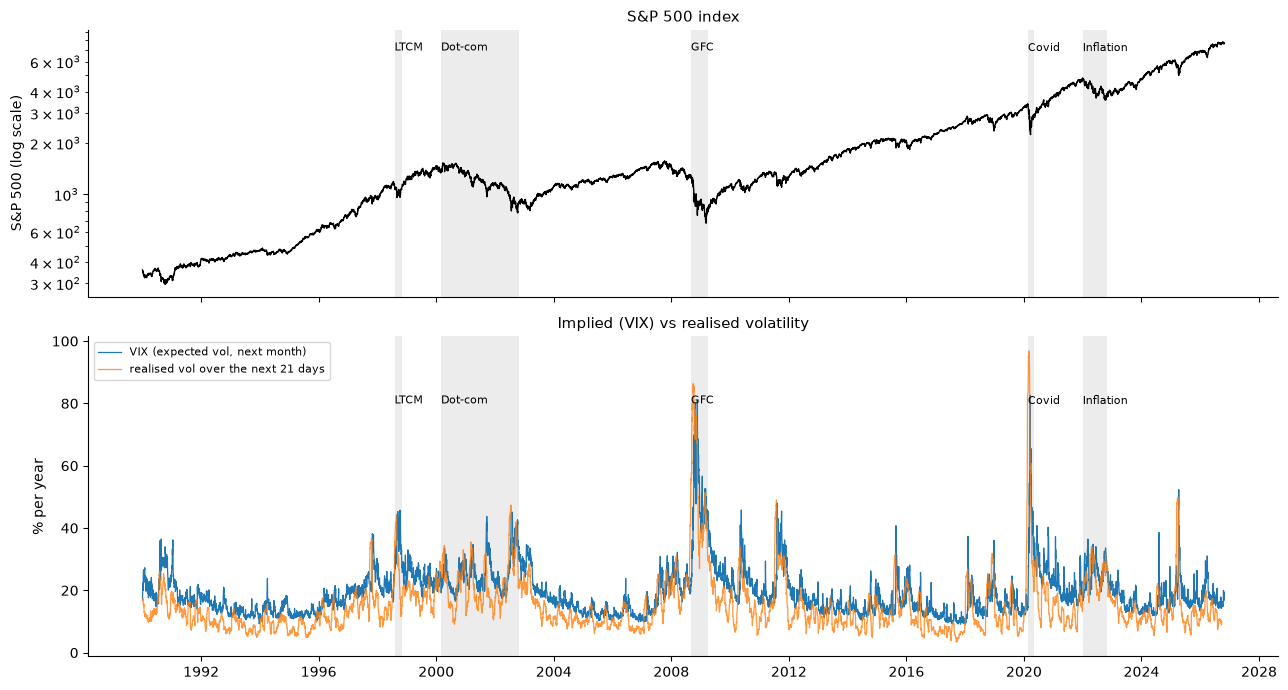

Average VIX 19.43, average realised vol 15.37, average premium 4.06 vol points
VIX above realised on 85.4% of days; largest shortfall -68.6 points on 2020-02-19


In [ ]:
# 1.7 Chart: S&P 500, VIX and realised volatility over the next 21 trading days

r_S = mkt["S"].pct_change()
realised_next = r_S.rolling(21).std().shift(-21) * np.sqrt(252) * 100   # vol of days t+1..t+21
fig = plot_market(mkt, realised_next)
fig.savefig(FIGURES / "market_history.png", dpi=150, bbox_inches="tight")
plt.show()

both = pd.concat([mkt["VIX"], realised_next], axis=1, keys=["VIX", "realised"]).dropna()
gap = both["VIX"] - both["realised"]
print(f"Average VIX {both['VIX'].mean():.2f}, average realised vol {both['realised'].mean():.2f}, "
      f"average premium {gap.mean():.2f} vol points")
print(f"VIX above realised on {(gap > 0).mean():.1%} of days; largest shortfall {gap.min():.1f} points "
      f"on {gap.idxmin().date()}")

**Findings – Section 1 (data).** 9,269 common days (2 January 1990 – 26 October 2026), no missing values. 34 VIX-only days (FRED publishes VIX on some US holidays since 2022) and 4 index-only days were dropped; 77 rate days filled from the previous day. Every extreme day is a real event, and index and VIX move in opposite directions (correlation −0.713): the largest VIX jump is +116% on 5 February 2018 (index −4.1%), and on the five worst index days VIX rose by 23–43%. VIX averaged 19.43 against 15.37 realised volatility: implied volatility is above realised on 85.4% of days (the variance risk premium) but can be far below it in a sudden crash (−68.6 points on 19 February 2020).

## 2. Black–Scholes prices and Greeks

Every risk number of the project is built on these two functions, so they are checked against hand-worked values, put–call parity, limits and finite differences.

### 2.1 Black–Scholes prices

| | |
|---|---|
| **1. What do I need to determine?** | A correct, vectorised Black–Scholes price for calls and puts with a dividend yield. |
| **2. What information and assumptions do I have?** | European options, constant σ, r, q over the option's life. |
| **3. Which method is appropriate?** | Closed form (Equation 3) with numpy arrays. |
| **4. Why should the method work?** | Black–Scholes is the market's quoting convention for index options; vectorisation lets full revaluation price millions of scenarios. |
| **5. How can I verify the answer?** | Theory-note values (120.16 / 109.76); put–call parity on 100,000 random options; limits T → 0 and σ → 0. |

In [ ]:
# 2.1 Black-Scholes prices: theory-note example, put-call parity, limits, vectorisation

S0, K0, T0, r0, q0, s0 = 5000, 5000, 21 / 252, 0.04, 0.015, 0.20
c, p = bs_price(S0, K0, T0, r0, q0, s0, "call"), bs_price(S0, K0, T0, r0, q0, s0, "put")
print(f"Theory example: call {c:.2f} (expected 120.16), put {p:.2f} (expected 109.76)")

rng = np.random.default_rng(0)
n = 100_000
S_, K_ = rng.uniform(1000, 8000, n), rng.uniform(1000, 8000, n)
T_, r_, q_, s_ = rng.uniform(0.01, 2, n), rng.uniform(0, 0.08, n), rng.uniform(0, 0.03, n), rng.uniform(0.05, 0.9, n)
gap = bs_price(S_, K_, T_, r_, q_, s_, "call") - bs_price(S_, K_, T_, r_, q_, s_, "put") \
      - (S_ * np.exp(-q_ * T_) - K_ * np.exp(-r_ * T_))
print(f"Put-call parity on {n:,} random options: largest error {np.abs(gap).max():.2e}")

for K_test in [4800, 5000, 5200]:
    near_expiry = bs_price(S0, K_test, 1e-8, r0, q0, s0, "call")
    no_vol = bs_price(S0, K_test, T0, r0, q0, 1e-8, "call")
    fwd_payoff = max(S0 * np.exp(-q0 * T0) - K_test * np.exp(-r0 * T0), 0)
    print(f"K={K_test}: T->0 {near_expiry:8.3f} (payoff {max(S0 - K_test, 0)}),  sigma->0 {no_vol:8.3f} (expected {fwd_payoff:.3f})")

S_grid = np.linspace(4000, 6000, 10_000)
print(f"\nVectorised: {bs_price(S_grid, K0, T0, r0, q0, s0, 'put').shape} put prices in one call")

Theory example: call 120.16 (expected 120.16), put 109.76 (expected 109.76)
Put-call parity on 100,000 random options: largest error 1.82e-12
K=4800: T->0  200.000 (payoff 200),  sigma->0  209.727 (expected 209.727)
K=5000: T->0    0.040 (payoff 0),  sigma->0   10.393 (expected 10.393)
K=5200: T->0    0.000 (payoff 0),  sigma->0    0.000 (expected 0.000)

Vectorised: (10000,) put prices in one call


### 2.2 The Greeks

| | |
|---|---|
| **1. What do I need to determine?** | Delta, gamma, vega and theta of each option. |
| **2. What information and assumptions do I have?** | Closed forms (Equation 5); theta as a one-day repricing. |
| **3. Which method is appropriate?** | Analytic derivatives, checked numerically. |
| **4. Why should the method work?** | The Greeks are exactly the inputs of the delta-normal and delta-gamma methods. |
| **5. How can I verify the answer?** | Finite differences on 2,000 random options; call–put relations; the theory-note straddle. |

In [ ]:
# 2.2 Greeks: theory-note values, finite differences, parity relations, straddle theta

gc = bs_greeks(S0, K0, T0, r0, q0, s0, "call")
gp = bs_greeks(S0, K0, T0, r0, q0, s0, "put")
print("Call:", {k: round(float(v), 5) for k, v in gc.items()})
print("Put :", {k: round(float(v), 5) for k, v in gp.items()})
print(f"Call delta - put delta = {gc['delta'] - gp['delta']:.6f}  (e^-qT = {np.exp(-q0 * T0):.6f});  "
      f"same gamma: {np.isclose(gc['gamma'], gp['gamma'])}, same vega: {np.isclose(gc['vega'], gp['vega'])}")

# Finite differences on random options
hS, hv = 1.0, 0.01
worst = {"delta": 0, "gamma": 0, "vega": 0}
for kind in ["call", "put"]:
    g = bs_greeks(S_[:2000], K_[:2000], T_[:2000], r_[:2000], q_[:2000], s_[:2000], kind)
    P = lambda S=S_[:2000], s=s_[:2000]: bs_price(S, K_[:2000], T_[:2000], r_[:2000], q_[:2000], s, kind)
    d_fd = (P(S=S_[:2000] + hS) - P(S=S_[:2000] - hS)) / (2 * hS)
    g_fd = (P(S=S_[:2000] + hS) - 2 * P() + P(S=S_[:2000] - hS)) / hS ** 2
    v_fd = (P(s=s_[:2000] + hv) - P(s=s_[:2000] - hv)) / 2
    worst["delta"] = max(worst["delta"], np.abs(g["delta"] - d_fd).max())
    worst["gamma"] = max(worst["gamma"], np.abs(g["gamma"] - g_fd).max())
    worst["vega"] = max(worst["vega"], np.abs(g["vega"] - v_fd).max())
print("Largest gap vs finite differences (2,000 random options, calls and puts):",
      {k: f"{v:.1e}" for k, v in worst.items()})

m = 10 * 100                                                       # 10 contracts x multiplier 100
print(f"\nLong straddle, 10 contracts: delta {m * (gc['delta'] + gp['delta']):.1f}, gamma {m * (gc['gamma'] + gp['gamma']):.3f}, "
      f"vega USD {m * (gc['vega'] + gp['vega']):,.0f} per vol point, theta USD {m * (gc['theta'] + gp['theta']):,.0f} per day")

Call: {'delta': 0.52524, 'gamma': 0.00138, 'vega': 5.73892, 'theta': -3.00793}
Put : {'delta': -0.47351, 'gamma': 0.00138, 'vega': 5.73892, 'theta': -2.51411}
Call delta - put delta = 0.998751  (e^-qT = 0.998751);  same gamma: True, same vega: True
Largest gap vs finite differences (2,000 random options, calls and puts): {'delta': '3.0e-06', 'gamma': '1.4e-08', 'vega': '1.5e-01'}

Long straddle, 10 contracts: delta 51.7, gamma 2.755, vega USD 11,478 per vol point, theta USD -5,522 per day


### 2.3 Vega check with a smaller step

| | |
|---|---|
| **1. What do I need to determine?** | Is the 0.15 vega gap of 2.2 an error in the formula or in the check? |
| **2. What information and assumptions do I have?** | A central difference has an error proportional to h². |
| **3. Which method is appropriate?** | Repeat with a 100× smaller step; compute relative gaps only where vega is not ~0. |
| **4. Why should the method work?** | If the formula is right, the gap must fall about 10,000×. |
| **5. How can I verify the answer?** | Gap 1.5e-01 → 1.5e-05. |

In [ ]:
# 2.3 Vega check with a 100x smaller step: the gap should shrink ~10,000x (central-difference error ~ h^2)
for kind in ["call", "put"]:
    g = bs_greeks(S_[:2000], K_[:2000], T_[:2000], r_[:2000], q_[:2000], s_[:2000], kind)
    big = g["vega"] > 0.01                                    # relative gap only where vega is not ~0 (far OTM)
    for h in [0.01, 0.0001]:
        P = lambda s: bs_price(S_[:2000], K_[:2000], T_[:2000], r_[:2000], q_[:2000], s, kind)
        v_fd = (P(s_[:2000] + h) - P(s_[:2000] - h)) / (2 * h) / 100       # per volatility point
        gap = np.abs(g["vega"] - v_fd)
        print(f"{kind:4s} step {h:<7}: largest gap {gap.max():.1e},  largest relative gap (vega > 0.01) "
              f"{(gap[big] / g['vega'][big]).max():.1e},  largest vega {g['vega'].max():.1f}")

call step 0.01   : largest gap 1.5e-01,  largest relative gap (vega > 0.01) 4.1e-01,  largest vega 36.6
call step 0.0001 : largest gap 1.5e-05,  largest relative gap (vega > 0.01) 4.0e-05,  largest vega 36.6
put  step 0.01   : largest gap 1.5e-01,  largest relative gap (vega > 0.01) 4.1e-01,  largest vega 36.6
put  step 0.0001 : largest gap 1.5e-05,  largest relative gap (vega > 0.01) 4.0e-05,  largest vega 36.6


**Findings – Section 2 (pricing).** Black–Scholes reproduces the theory-note prices exactly (120.16 / 109.76), put–call parity holds to 1.8e-12 and the limits are right. Delta and gamma match finite differences to 3e-6 and 1e-8; the vega gap falls 10,000× when the step is 100× smaller, so it was the check's h² error, not the formula. A 10-contract ATM straddle: delta 51.7, gamma 2.75, vega USD 11,478 per vol point, theta −USD 5,522 a day.

## 3. The options book and its realised P&L

The three sub-books, their value and Greeks, and the P&L they would really have made every day from 1990 to 2026 — the target that every VaR forecast is tested against.

### 3.1 The book: positions and value

| | |
|---|---|
| **1. What do I need to determine?** | The legs of the book and its value, now and for other index levels. |
| **2. What information and assumptions do I have?** | `BOOK_SPEC`: long ATM straddle, short 95% puts, long ATM / short 105% call spread, 10 contracts each, multiplier 100. |
| **3. Which method is appropriate?** | Strikes = moneyness × S; value = Σ contracts × 100 × Black–Scholes price. |
| **4. Why should the method work?** | A book is the sum of its legs; the value profile shows where the book gains and loses. |
| **5. How can I verify the answer?** | Straddle value = 10 × 100 × (120.16 + 109.76); total = sum of sub-books. |

In [ ]:
# 3.1 The book: legs and value at the theory-note market, and on a range of index levels

legs = book_legs(S0)
print(legs.to_string(index=False))

val = book_value(legs, S0, T0, r0, q0, s0)
print("\nValue at S = 5,000, sigma = 20%, one month (USD):")
print({k: round(float(v), 0) for k, v in val.items()})

S_grid = np.linspace(4250, 5750, 7)
grid = book_value(legs, S_grid, T0, r0, q0, s0)
print("\nValue on a range of index levels (USD):")
print(pd.DataFrame(grid, index=S_grid.round(0)).round(0).to_string())

     sub-book kind  moneyness  contracts  strike
long straddle call       1.00         10  5000.0
long straddle  put       1.00         10  5000.0
   short puts  put       0.95        -10  4750.0
  call spread call       1.00         10  5000.0
  call spread call       1.05        -10  5250.0

Value at S = 5,000, sigma = 20%, one month (USD):
{'long straddle': 229920.0, 'short puts': -26942.0, 'call spread': 85247.0, 'total': 288225.0}

Value on a range of index levels (USD):
        long straddle  short puts  call spread      total
4250.0       739104.0   -492434.0        207.0   246877.0
4500.0       497004.0   -266535.0       3643.0   234111.0
4750.0       300763.0   -104275.0      25442.0   221929.0
5000.0       229920.0    -26942.0      85247.0   288225.0
5250.0       321420.0     -4430.0     164586.0   481576.0
5500.0       521171.0      -466.0     220336.0   741040.0
5750.0       760869.0       -32.0     242723.0  1003560.0


### 3.2 Greeks of the book

| | |
|---|---|
| **1. What do I need to determine?** | The book's sensitivities by sub-book. |
| **2. What information and assumptions do I have?** | Greeks are additive across legs. |
| **3. Which method is appropriate?** | Σ contracts × 100 × option Greek. |
| **4. Why should the method work?** | The Greeks summarise the book's local shape: direction (delta), curvature (gamma), volatility (vega), time (theta). |
| **5. How can I verify the answer?** | Finite differences on the whole book (±1 index point). |

In [ ]:
# 3.2 Greeks of the book, and a finite-difference check of delta and gamma

G = book_greeks(legs, S0, T0, r0, q0, s0)
print(G.round(2).to_string())

h = 1.0
v_up, v_0, v_dn = (book_value(legs, S0 + d, T0, r0, q0, s0) for d in (h, 0, -h))
fd = pd.DataFrame({k: {"delta FD": (v_up[k] - v_dn[k]) / (2 * h), "gamma FD": (v_up[k] - 2 * v_0[k] + v_dn[k]) / h ** 2}
                   for k in v_0}).T
print("\nFinite differences (+/-1 index point):")
print(fd.round(4).to_string())
print(f"\nLargest gap: delta {np.abs(G['delta'] - fd['delta FD']).max():.1e}, gamma {np.abs(G['gamma'] - fd['gamma FD']).max():.1e}")

                delta  gamma      vega    theta
long straddle   51.72   2.75  11477.85 -5522.04
short puts     169.99  -0.88  -3650.69  1655.52
call spread    307.85   0.36   1496.70  -880.09
total          529.56   2.24   9323.85 -4746.61

Finite differences (+/-1 index point):
               delta FD  gamma FD
long straddle   51.7228    2.7547
short puts     169.9872   -0.8762
call spread    307.8477    0.3592
total          529.5578    2.2377

Largest gap: delta 5.2e-04, gamma 3.6e-06


### 3.3 The realised daily P&L, 1990–2026

| | |
|---|---|
| **1. What do I need to determine?** | What the book would really have made each day. |
| **2. What information and assumptions do I have?** | Book built on day t−1, revalued on day t with one day less to expiry; also an index-only version with the VIX held. |
| **3. Which method is appropriate?** | Vectorised full revaluation over all days. |
| **4. Why should the method work?** | This clean (hypothetical) P&L is the standard target of VaR backtests. |
| **5. How can I verify the answer?** | One day checked by hand with `book_value`. |

In [ ]:
# 3.3 Realised daily P&L of the book (full, and index-only with VIX held), checks and worst days

Q = 0.015
pnl = daily_book_pnl(mkt, Q)
pnl_idx = daily_book_pnl(mkt, Q, hold_vol=True)
print(f"{len(pnl):,} days, {pnl.index[0].date()} to {pnl.index[-1].date()}")

# Check one day by hand with book_value
d = pd.Timestamp("2020-03-16"); p = mkt.index[mkt.index.get_loc(d) - 1]
lg = book_legs(mkt.loc[p, "S"])
before = book_value(lg, mkt.loc[p, "S"], 21 / 252, mkt.loc[p, "r"], Q, mkt.loc[p, "sigma"])
after = book_value(lg, mkt.loc[d, "S"], 20 / 252, mkt.loc[d, "r"], Q, mkt.loc[d, "sigma"])
print(f"Check {d.date()}: vectorised total {pnl.loc[d, 'total']:,.0f} vs by hand {after['total'] - before['total']:,.0f}")

print("\nDaily P&L statistics (USD):")
print(pd.DataFrame({"mean": pnl.mean(), "std": pnl.std(), "worst": pnl.min(), "worst day": pnl.idxmin().dt.date,
                    "best": pnl.max(), "best day": pnl.idxmax().dt.date}).round(0).to_string())

print("\nFull vs index-only P&L on selected days (USD):")
sel = pd.to_datetime(["2008-10-15", "2018-02-05", "2020-03-16", "2024-08-05"])
print(pd.concat({"full": pnl.loc[sel], "index only": pnl_idx.loc[sel]}, axis=1).round(0).to_string())
pnl.to_csv(OUT / "pnl_realised.csv")

9,268 days, 1990-01-03 to 2026-10-26
Check 2020-03-16: vectorised total -64,627 vs by hand -64,627

Daily P&L statistics (USD):
                mean      std     worst   worst day      best    best day
long straddle -660.0  10317.0 -130988.0  2024-08-06  215939.0  2025-04-04
short puts      86.0   9562.0 -221009.0  2020-03-16  166863.0  2025-04-09
call spread    308.0   6344.0  -45989.0  2025-04-03   83452.0  2025-04-09
total         -266.0   9491.0  -72333.0  2020-03-20  220887.0  2025-04-09

Full vs index-only P&L on selected days (USD):
                    full                                    index only                                 
           long straddle short puts call spread    total long straddle short puts call spread     total
date                                                                                                   
2008-10-15       38890.0   -54250.0     -8346.0 -23707.0       13030.0   -40063.0    -10348.0  -37381.0
2018-02-05      134300.0   -87755.0   

### 3.4 A constant-notional book

| | |
|---|---|
| **1. What do I need to determine?** | A book whose size does not grow with the index. |
| **2. What information and assumptions do I have?** | Fixed 10 contracts would make the book 21× larger in 2026 than in 1990. |
| **3. Which method is appropriate?** | Scale the contracts daily: USD 5m of index notional per 10 contracts. |
| **4. Why should the method work?** | Constant size makes P&L and VaR comparable across decades. |
| **5. How can I verify the answer?** | Scaled P&L = fixed-contract P&L × 5,000 / S. |

In [ ]:
# 3.4 Constant-notional book (USD 5m per 10 contracts): check, statistics by decade, worst days

pnl = daily_book_pnl(mkt, Q, notional=NOTIONAL)
pnl_idx = daily_book_pnl(mkt, Q, hold_vol=True, notional=NOTIONAL)
raw = daily_book_pnl(mkt, Q)                                          # fixed 10 contracts, for the check

d = pd.Timestamp("2024-01-24"); p = mkt.index[mkt.index.get_loc(d) - 1]
print(f"Check {d.date()}: scaled {pnl.loc[d, 'total']:,.1f} vs fixed x 5000/S {raw.loc[d, 'total'] * 5000 / mkt.loc[p, 'S']:,.1f}")

print("\nStandard deviation of daily P&L by decade (USD):")
print(pnl.groupby((pnl.index.year // 10) * 10).std().round(0).to_string())

print("\nWorst 6 days of the whole book, and the index and VIX moves those days:")
w = pnl["total"].nsmallest(6).index
print(pd.DataFrame({"book P&L": pnl.loc[w, "total"], "short puts": pnl.loc[w, "short puts"],
                    "index %": 100 * mkt["S"].pct_change().loc[w], "VIX before": mkt["VIX"].shift(1).loc[w],
                    "VIX": mkt["VIX"].loc[w]}).round(1).to_string())
pnl.to_csv(OUT / "pnl_realised.csv"); pnl_idx.to_csv(OUT / "pnl_index_only.csv")

Check 2024-01-24: scaled 5,408.3 vs fixed x 5000/S 5,408.3

Standard deviation of daily P&L by decade (USD):
      long straddle  short puts  call spread    total
date                                                 
1990        13428.0     13091.0      12338.0  19411.0
2000        19121.0     26534.0      14856.0  28415.0
2010        19150.0     16457.0      11699.0  14811.0
2020        24966.0     26191.0      13468.0  24358.0

Worst 6 days of the whole book, and the index and VIX moves those days:
            book P&L  short puts  index %  VIX before   VIX
date                                                       
2020-03-20 -150107.0    -46497.6     -4.3        72.0  66.0
2008-10-09 -137008.0   -193152.9     -7.6        57.5  63.9
2020-03-18 -134038.2   -100275.7     -5.2        75.9  76.4
2008-11-20 -132271.5   -168572.7     -6.7        74.3  80.9
2008-12-01 -124714.6   -261182.9     -8.9        55.8  68.5
2008-10-07 -123621.1   -120070.6     -5.7        52.0  53.7


**Findings – Section 3 (book).** At S = 5,000 the book is worth USD 288k with delta 530, gamma +2.24, vega +9,324 and theta −4,747 a day: long gamma overall, but the short puts (gamma −0.88) dominate around 4,750, where the book loses USD 66k — **the worst outcome is a moderate fall, not a crash**, which Greeks at S = 5,000 cannot show. The realised P&L is checked by hand to the dollar. Vega dominates on volatility shocks: on 5 February 2018 and 5 August 2024 the VIX move turns an index-only loss into a gain. With constant notional the daily std is 15–28k by decade; the worst days (−150k on 20 March 2020, −137k on 9 October 2008) are in crises.

## 4. Risk factors

The pricing volatility (VIX) is not necessarily the best risk volatility. Here we choose the volatility forecast and measure how far the two risk factors — index returns and VIX changes — are from normal.

### 4.1 Which volatility should the risk model use?

| | |
|---|---|
| **1. What do I need to determine?** | The best forecast of tomorrow's index volatility: VIX or EWMA? |
| **2. What information and assumptions do I have?** | VIX is known on day t−1; EWMA (λ = 0.94) uses past returns only. |
| **3. Which method is appropriate?** | Compare with QLIKE (lower is better), breach rate of a 99% normal VaR and the std of r/σ. |
| **4. Why should the method work?** | QLIKE is the loss that ranks variance forecasts correctly even with noisy realised returns. |
| **5. How can I verify the answer?** | Breach rate ~1% and std of r/σ ~1 for a well-scaled forecast. |

In [ ]:
# 4.1 Risk-model volatility: VIX/sqrt(252) vs EWMA as forecasts of tomorrow's index return

ret = mkt["S"].pct_change().dropna()
fc = pd.DataFrame({"VIX": (mkt["VIX"].shift(1) / 100 / np.sqrt(252)).loc[ret.index],   # known on day t-1
                   "EWMA": ewma_vol(ret)}).iloc[250:]
r = ret.loc[fc.index]
z = 2.3263

rows = {}
for name, sig in fc.items():
    rows[name] = {"avg vol % a year": 100 * np.sqrt(252) * sig.mean(),
                  "QLIKE": (np.log(sig ** 2) + r ** 2 / sig ** 2).mean(),
                  "breach rate %": 100 * (r < -z * sig).mean(),
                  "std of r/sigma": (r / sig).std()}
print(f"{len(r):,} days, {r.index[0].date()} to {r.index[-1].date()}")
print(pd.DataFrame(rows).T.round(3).to_string())

print("\nBreach rate (%) by period:")
periods = {"1991-2007": ("1991", "2007"), "2008-09": ("2008", "2009"), "2010-19": ("2010", "2019"),
           "2020": ("2020", "2020"), "2021-26": ("2021", "2026")}
print(pd.DataFrame({name: {p: 100 * (r.loc[a:b] < -z * sig.loc[a:b]).mean() for p, (a, b) in periods.items()}
                    for name, sig in fc.items()}).round(2).to_string())

9,018 days, 1990-12-28 to 2026-10-26
      avg vol % a year  QLIKE  breach rate %  std of r/sigma
VIX             19.325 -8.337          0.665           0.778
EWMA            15.607 -8.366          2.029           1.051

Breach rate (%) by period:
            VIX  EWMA
1991-2007  0.37  1.75
2008-09    1.39  1.78
2010-19    0.87  2.34
2020       2.37  4.74
2021-26    0.62  1.92


### 4.2 The two risk factors: tails and dependence

| | |
|---|---|
| **1. What do I need to determine?** | How non-normal the standardised index returns and VIX changes are, and how they move together. |
| **2. What information and assumptions do I have?** | EWMA-standardised shocks. |
| **3. Which method is appropriate?** | Skewness, kurtosis and tail quantiles; correlation by period and on crash days. |
| **4. Why should the method work?** | Options lose most when index and implied volatility move together; their joint behaviour drives the tails. |
| **5. How can I verify the answer?** | Normal benchmarks: skew 0, excess kurtosis 0, 1% quantile −2.326. |

In [ ]:
# 4.2 The two risk factors: standardised shocks (tails), and how index and VIX move together

dlv = np.log(mkt["VIX"]).diff().dropna()                        # VIX log change
fac = pd.DataFrame({"index return": ret, "VIX log change": dlv.loc[ret.index]})
sig_f = pd.DataFrame({c: ewma_vol(fac[c]) for c in fac})
zf = (fac / sig_f).iloc[250:]                                     # standardised shocks

rows = {}
for c in zf:
    x = zf[c]
    rows[c] = {"std": x.std(), "skew": stats.skew(x), "excess kurtosis": stats.kurtosis(x),
               "1% quantile": x.quantile(0.01), "99% quantile": x.quantile(0.99)}
print("Standardised shocks (normal: std 1, skew 0, kurtosis 0, quantiles -2.326 / +2.326):")
print(pd.DataFrame(rows).T.round(3).to_string())

f = fac.loc[zf.index]
print("\nCorrelation of index return and VIX log change by period:")
print({p: round(f.loc[a:b].corr().iloc[0, 1], 3) for p, (a, b) in periods.items()})

tail = f["index return"] <= f["index return"].quantile(0.01)
print(f"\nOn the index's 1% worst days ({tail.sum()} days): VIX rose on {(f.loc[tail, 'VIX log change'] > 0).mean():.0%} of them, "
      f"average VIX change {100 * np.expm1(f.loc[tail, 'VIX log change']).mean():+.1f}% "
      f"(all days: {100 * np.expm1(f['VIX log change']).mean():+.1f}%)")
print(f"Correlation on those days: {f.loc[tail].corr().iloc[0, 1]:.3f}")

Standardised shocks (normal: std 1, skew 0, kurtosis 0, quantiles -2.326 / +2.326):
                  std   skew  excess kurtosis  1% quantile  99% quantile
index return    1.051 -0.564            2.724       -2.876         2.443
VIX log change  1.079  1.220            6.766       -2.294         3.233

Correlation of index return and VIX log change by period:
{'1991-2007': np.float64(-0.696), '2008-09': np.float64(-0.814), '2010-19': np.float64(-0.806), '2020': np.float64(-0.725), '2021-26': np.float64(-0.77)}

On the index's 1% worst days (91 days): VIX rose on 99% of them, average VIX change +22.1% (all days: +0.2%)
Correlation on those days: -0.183


**Findings – Section 4 (risk factors).** VIX is a biased risk volatility: too high on average (VaR breached on only 0.67% of days, std of r/σ 0.78) yet too slow in crashes; **EWMA has the better QLIKE (−8.366 vs −8.337)** and becomes the risk volatility, with the VIX kept for pricing. Even after EWMA standardisation both factors are far from normal: index shocks have skew −0.56, excess kurtosis 2.7 and a 1% quantile of −2.88 (normal −2.33); VIX changes are right-skewed (+1.22) with excess kurtosis 6.8. On the index's 1% worst days VIX rose on 99% of them, by +22% on average: crash and volatility spike come together.

## 5. The three VaR methods on today's book

Delta-normal, delta-gamma and Monte Carlo with full revaluation, on the theory-note market (S = 5,000, σ = 20%), with full revaluation as the reference.

### 5.1 Delta-normal and delta-gamma VaR

| | |
|---|---|
| **1. What do I need to determine?** | VaR from the Greeks: linear (DN) and quadratic (DG). |
| **2. What information and assumptions do I have?** | Greeks at the theory-note market; σ_d = 20%/√252. |
| **3. Which method is appropriate?** | DN = z |Δ| S σ_d; DG by Cornish–Fisher and by the exact quantile of the quadratic. |
| **4. Why should the method work?** | The quadratic adds the curvature that a straddle or short put has. |
| **5. How can I verify the answer?** | Theory-note short straddle 7,580 / 42,268 / 38,950; Γ = 0 gives identical answers. |

In [ ]:
# 5.1 Delta-normal and delta-gamma VaR: theory-note check, the Gamma = 0 case, and today's book

sd0 = s0 / np.sqrt(252)
st = G.loc["long straddle"]                                                 # Greeks at the theory-note market
for name, sign in [("short straddle", -1), ("long straddle", +1)]:
    d, g = sign * st["delta"], sign * st["gamma"]
    print(f"{name:15s}: delta-normal {var_delta_normal(d, S0, sd0):9,.0f}   "
          f"Cornish-Fisher {var_cornish_fisher(d, g, 0, S0, sd0):9,.0f}   exact quadratic {var_delta_gamma_mc(d, g, 0, S0, sd0):9,.0f}")
print("Expected short straddle: 7,580 / 42,268 / 38,950")

print(f"\nGamma = 0 (delta 530): DN {var_delta_normal(530, S0, sd0):,.1f}, CF {var_cornish_fisher(530, 0, 0, S0, sd0):,.1f}, "
      f"exact {var_delta_gamma_mc(530, 0, 0, S0, sd0):,.1f}")

print("\nEach sub-book and the whole book at S = 5,000, sigma_d = 20%/sqrt(252), theta included:")
rows = {}
for b, g in G.iterrows():
    rows[b] = {"delta-normal": var_delta_normal(g["delta"], S0, sd0),
               "Cornish-Fisher": var_cornish_fisher(g["delta"], g["gamma"], g["theta"], S0, sd0),
               "exact quadratic": var_delta_gamma_mc(g["delta"], g["gamma"], g["theta"], S0, sd0)}
print(pd.DataFrame(rows).T.round(0).to_string())

short straddle : delta-normal     7,580   Cornish-Fisher    42,268   exact quadratic    38,950
long straddle  : delta-normal     7,580   Cornish-Fisher    -3,240   exact quadratic       485
Expected short straddle: 7,580 / 42,268 / 38,950

Gamma = 0 (delta 530): DN 77,669.5, CF 77,669.5, exact 77,714.9

Each sub-book and the whole book at S = 5,000, sigma_d = 20%/sqrt(252), theta included:
               delta-normal  Cornish-Fisher  exact quadratic
long straddle        7580.0          2282.0           6007.0
short puts          24911.0         33184.0          32689.0
call spread         45114.0         42201.0          42159.0
total               77605.0         59909.0          58340.0


### 5.2 Monte Carlo with full revaluation

| | |
|---|---|
| **1. What do I need to determine?** | The exact VaR of today's book under normal index moves, and the error of DN and DG. |
| **2. What information and assumptions do I have?** | 1,000,000 normal returns; every option repriced. |
| **3. Which method is appropriate?** | Full revaluation (Equation 12). |
| **4. Why should the method work?** | No Taylor approximation: the only error is sampling noise. |
| **5. How can I verify the answer?** | Theory-note straddles (5,971 / 32,959); a forward (linear) equals delta-normal. |

In [ ]:
# 5.2 Monte Carlo VaR/ES with full revaluation: checks, then all three methods side by side

rng = np.random.default_rng(1)
ret_sim = rng.normal(0, sd0, 1_000_000)

# Check 1: theory-note straddles (built from the straddle legs only)
st_legs = legs[legs["sub-book"] == "long straddle"]
pl = full_reval_pnl(st_legs, S0, r0, q0, s0, ret_sim)["total"]
print(f"Long straddle full reval VaR {var_es(pl)[0]:,.0f} (expected 5,971);  short straddle {var_es(-pl)[0]:,.0f} (expected 32,959)")

# Check 2: a forward (long call + short put, same strike) behaves like delta-normal
fwd = pd.DataFrame([("forward", "call", 1.0, 10, S0), ("forward", "put", 1.0, -10, S0)],
                   columns=["sub-book", "kind", "moneyness", "contracts", "strike"])
gf = book_greeks(fwd, S0, T0, r0, q0, s0).loc["total"]
print(f"Forward: full reval {var_es(full_reval_pnl(fwd, S0, r0, q0, s0, ret_sim)['total'])[0]:,.0f}  "
      f"vs delta-normal {var_delta_normal(gf['delta'], S0, sd0):,.0f}")

# All methods, today's book at the theory-note market
mc = full_reval_pnl(legs, S0, r0, q0, s0, ret_sim)
rows = {}
for b, g in G.iterrows():
    v_mc, es_mc = var_es(mc[b])
    rows[b] = {"delta-normal": var_delta_normal(g["delta"], S0, sd0),
               "delta-gamma": var_delta_gamma_mc(g["delta"], g["gamma"], g["theta"], S0, sd0),
               "MC full reval": v_mc, "MC ES 97.5": es_mc}
tab = pd.DataFrame(rows).T
tab["DN error %"] = 100 * (tab["delta-normal"] / tab["MC full reval"] - 1)
tab["DG error %"] = 100 * (tab["delta-gamma"] / tab["MC full reval"] - 1)
print("\n", tab.round(1).to_string())

Long straddle full reval VaR 5,971 (expected 5,971);  short straddle 32,962 (expected 32,959)
Forward: full reval 147,073  vs delta-normal 146,363

                delta-normal  delta-gamma  MC full reval  MC ES 97.5  DN error %  DG error %
long straddle        7579.8       6006.7         5971.4      5970.3        26.9         0.6
short puts          24910.9      32689.1        33695.9     34203.5       -26.1        -3.0
call spread         45114.0      42158.8        41289.8     41254.7         9.3         2.1
total               77604.7      58340.1        57575.3     57235.2        34.8         1.3


**Findings – Section 5 (methods today).** The functions reproduce the theory-note numbers, and with Γ = 0 all methods agree. With full revaluation as the reference (straddle 5,971; short puts 33,696; call spread 41,290; book 57,575), **delta-normal is wrong in both directions**: −26% for the short puts (it ignores negative gamma), +27% for the long straddle, +35% for the book. Delta-gamma (exact quadratic) is within 3%. Cornish–Fisher is unreliable: −3,240 for the long straddle (a negative VaR).

## 6. When do the approximations fail?

The same comparison for volatilities from 10% to 80% and horizons of 1 and 10 days.

### 6.1 Accuracy vs move size

| | |
|---|---|
| **1. What do I need to determine?** | How the DN and DG errors grow with volatility and horizon. |
| **2. What information and assumptions do I have?** | Volatility 10–80%; horizons 1 and 10 days; same book. |
| **3. Which method is appropriate?** | Compare each with full revaluation on 400,000 scenarios. |
| **4. Why should the method work?** | Taylor expansions are local: their error grows with the size of the move. |
| **5. How can I verify the answer?** | DG error near 0 for small moves. |

In [ ]:
# 6.1 Accuracy vs move size: delta-normal and delta-gamma errors against full revaluation
rng = np.random.default_rng(2)
z_sim = rng.standard_normal(400_000)
rows = {}
for h in (1, 10):
    for vol in (0.10, 0.20, 0.40, 0.60, 0.80):
        sd_h = vol * np.sqrt(h / 252)                                   # std of the h-day return
        Gv = book_greeks(legs, S0, T0, r0, q0, vol)                     # Greeks at this volatility
        mcv = full_reval_pnl(legs, S0, r0, q0, vol, z_sim * sd_h, dt=h / 252)
        for b in ["short puts", "total"]:
            g = Gv.loc[b]
            full = var_es(mcv[b])[0]
            dn = var_delta_normal(g["delta"], S0, sd_h)
            dg = var_delta_gamma_mc(g["delta"], g["gamma"], h * g["theta"], S0, sd_h, n=400_000)
            rows[(h, int(vol * 100), b)] = {"1% move %": -100 * 2.326 * sd_h, "full reval": full,
                                            "DN error %": 100 * (dn / full - 1), "DG error %": 100 * (dg / full - 1)}
out = pd.DataFrame(rows).T
out.index.names = ["days", "vol %", "book"]
print(out.round(1).to_string())

                       1% move %  full reval  DN error %  DG error %
days vol % book                                                     
1    10    short puts       -1.5      3614.7       -36.8        -6.4
           total            -1.5     26713.0        59.0         2.5
     20    short puts       -2.9     33830.4       -26.4        -3.1
           total            -2.9     57656.7        34.6         1.3
     40    short puts       -5.9    112223.8       -21.3        -2.0
           total            -5.9    125223.3        23.4         1.1
     60    short puts       -8.8    190392.7       -20.1        -2.0
           total            -8.8    194813.6        21.0         1.4
     80    short puts      -11.7    265952.5       -19.8        -2.2
           total           -11.7    266810.9        20.2         1.7
10   10    short puts       -4.6     27616.9       -73.9       -33.8
           total            -4.6     60624.9       121.5         2.2
     20    short puts       -9.3  

### 6.2 Chart: P&L profiles and approximation errors

| | |
|---|---|
| **1. What do I need to determine?** | A picture of why the approximations fail. |
| **2. What information and assumptions do I have?** | Short puts, S = 5,000, σ = 20%; the 6.1 table. |
| **3. Which method is appropriate?** | Plot full, delta and delta-gamma P&L against the index move; plot the 6.1 errors. |
| **4. Why should the method work?** | The VaR error is the gap between the curves at the 1% move. |
| **5. How can I verify the answer?** | Same numbers as 6.1. |

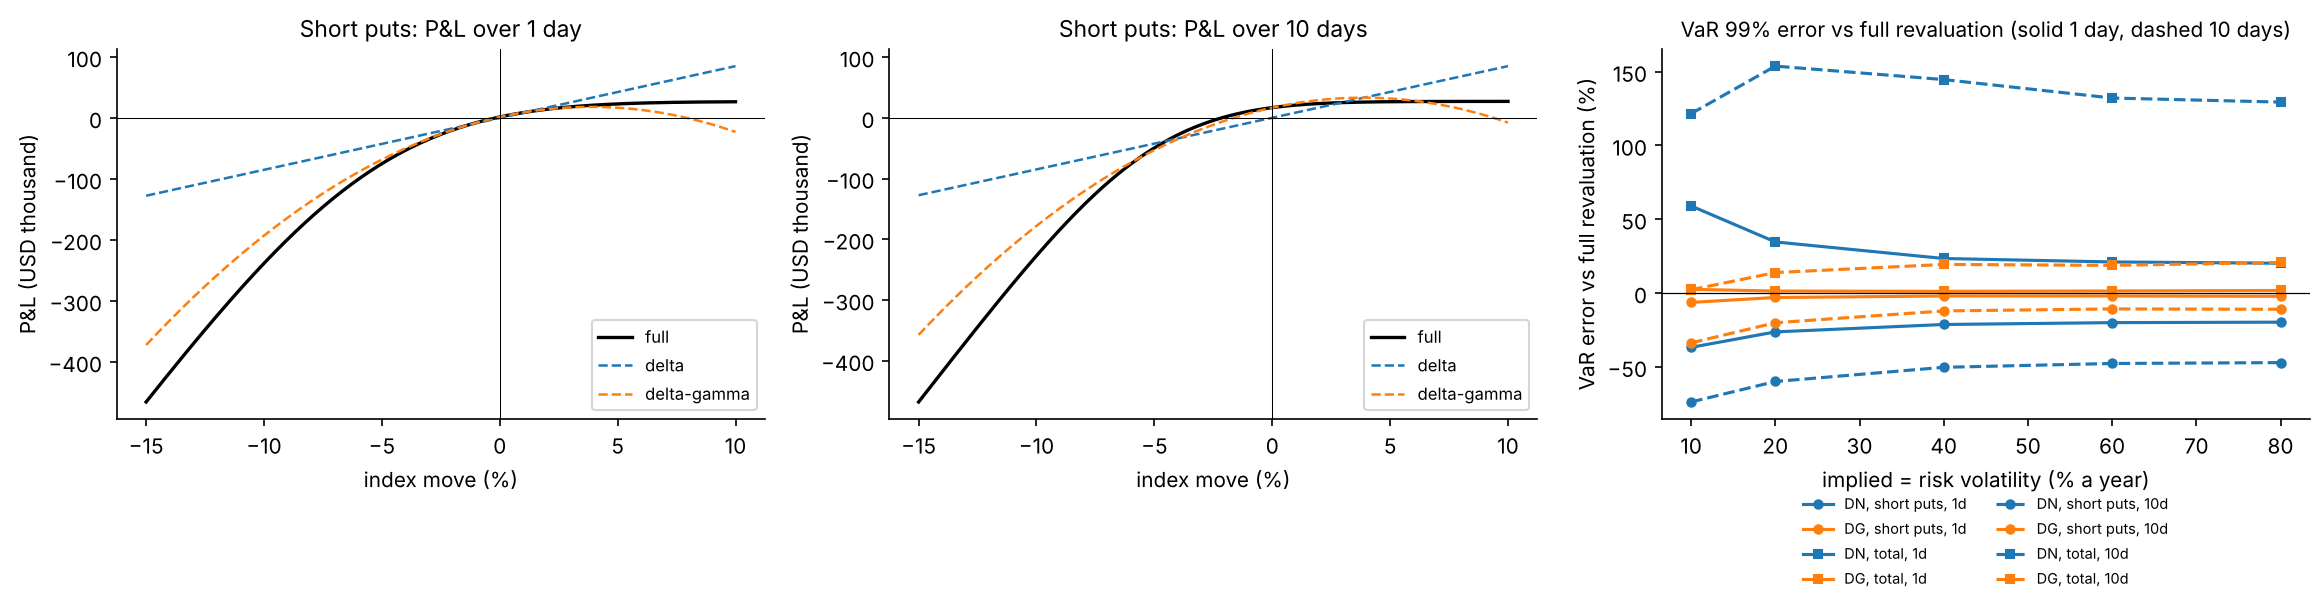

Short puts P&L (USD) for selected index moves:
          1 day                        10 days                     
           full    delta delta-gamma      full    delta delta-gamma
-10.0 -238309.0 -84993.0   -192859.0 -227119.0 -84993.0   -177959.0
-5.0   -74945.0 -42497.0    -68221.0  -49578.0 -42497.0    -53322.0
-2.0   -19771.0 -16999.0    -19724.0    1443.0 -16999.0     -4824.0
 2.0    14268.0  16999.0     14273.0   23431.0  16999.0     29173.0
 5.0    23050.0  42497.0     16772.0   26411.0  42497.0     31672.0


In [ ]:
# 6.2 Chart: short puts' P&L profile (full vs delta vs delta-gamma) at 1 and 10 days, and the 6.1 VaR errors
moves = np.linspace(-0.15, 0.10, 251)                                   # index moves from -15% to +10%
gsp = G.loc["short puts"]                                               # Greeks at S = 5,000, sigma 20%
dS = moves * S0
profiles = {}
for label, h in [("1 day", 1), ("10 days", 10)]:
    profiles[label] = pd.DataFrame({
        "full": full_reval_pnl(legs, S0, r0, q0, s0, moves, dt=h / 252)["short puts"],
        "delta": gsp["delta"] * dS,
        "delta-gamma": h * gsp["theta"] + gsp["delta"] * dS + 0.5 * gsp["gamma"] * dS ** 2}, index=100 * moves)
fig = plot_approximations(profiles, out)
fig.savefig(FIGURES / "approximations.png", dpi=150, bbox_inches="tight")
plt.show()

print("Short puts P&L (USD) for selected index moves:")
sel = [-10.0, -5.0, -2.0, 2.0, 5.0]
print(pd.concat({k: p.loc[np.isin(p.index.round(1), sel)].round(0) for k, p in profiles.items()}, axis=1).to_string())

**Findings – Section 6 (accuracy).** At one day, DG stays within about 6% at every volatility while DN is 20–37% too low for the short puts and 20–59% too high for the book. **At ten days the Taylor expansion breaks**: DN is 47–74% too low for the short puts and 121–154% too high for the book; even DG is 11–34% too low for the short puts (the put's delta keeps growing beyond the quadratic) and 14–21% too high for the book (its payoff is capped by the call spread, the quadratic is not). The profiles show why: at −10% in one day the short puts lose 238k, delta says 85k, delta-gamma 193k.

## 7. Out-of-sample VaR / ES and backtests

A daily engine that forecasts VaR and ES with every method using only past data, run from 1993 to 2026, and backtested.

### 7.1 The out-of-sample engine

| | |
|---|---|
| **1. What do I need to determine?** | A daily engine that forecasts VaR/ES with DN, DG, MC and FHS using only past data. |
| **2. What information and assumptions do I have?** | Book of day t−1, volatility forecast for day t, 1,000 past standardised returns. |
| **3. Which method is appropriate?** | Loop over days; common random numbers; scale to the constant notional. |
| **4. Why should the method work?** | Every forecast uses exactly the information a risk manager had that evening. |
| **5. How can I verify the answer?** | A fake −30% day changes nothing before it; one day reproduced by hand. |

In [ ]:
# 7.1 Engine: look-ahead test on a short period, and a hand check on one day

ewma = ewma_vol(ret)
j0 = 5000
base = rolling_option_var(mkt, ewma, Q, start=j0 - 2, end=j0 + 3)

mkt_f = mkt.copy()
mkt_f.iloc[j0 + 1:, mkt_f.columns.get_loc("S")] *= 0.70          # a fake -30% day: return j0 is -30%
ret_f = mkt_f["S"].pct_change().iloc[1:]
fake = rolling_option_var(mkt_f, ewma_vol(ret_f), Q, start=j0 - 2, end=j0 + 3)
col = ("total", "FHS", "VaR")
print(f"Fake -30% return on {ret.index[j0].date()}:")
print(pd.DataFrame({"base": base[col], "with fake crash": fake[col]}).round(0).to_string())
upto = ret.index[j0]
print(f"All forecasts up to and including that day unchanged: {np.allclose(base.loc[:upto].values, fake.loc[:upto].values)}")

# Hand check on one day with the step-5 functions
d = base.index[0]; t = ret.index.get_loc(d); prev = mkt.iloc[t]
size = 5_000_000 / (100 * 10 * prev["S"])
lg = book_legs(prev["S"]); Gd = book_greeks(lg, prev["S"], 21 / 252, prev["r"], Q, prev["sigma"]).loc["short puts"]
print(f"\nHand check {d.date()}, short puts: DN engine {base.loc[d, ('short puts', 'DN', 'VaR')]:,.1f} "
      f"vs hand {size * var_delta_normal(Gd['delta'], prev['S'], ewma.iloc[t]):,.1f}")

Fake -30% return on 2009-11-05:
               base  with fake crash
date                                
2009-11-03  76084.0          76084.0
2009-11-04  73387.0          73387.0
2009-11-05  70520.0          70520.0
2009-11-06  68892.0          92062.0
2009-11-09  65568.0          84618.0
All forecasts up to and including that day unchanged: True

Hand check 2009-11-03, short puts: DN engine 40,264.7 vs hand 40,264.7


### 7.2 Full out-of-sample run

| | |
|---|---|
| **1. What do I need to determine?** | VaR/ES forecasts for every day from 1993 to 2026. |
| **2. What information and assumptions do I have?** | EWMA volatility; 8,268 days. |
| **3. Which method is appropriate?** | Run once, save, reload. |
| **4. Why should the method work?** | Saving avoids recomputing 5 minutes of work. |
| **5. How can I verify the answer?** | Dates aligned with the P&L, no missing values; first breach counts. |

In [ ]:
# 7.2 Full out-of-sample (oos) run (computed once, saved, reloaded afterwards), first look at breaches

oos_file = OUT / "var_oos.pkl"
if oos_file.exists():
    oos = pd.read_pickle(oos_file)
    print("Loaded from data/processed")
else:
    t0 = time.time()
    oos = rolling_option_var(mkt, ewma, Q, start=1000)
    oos.to_pickle(oos_file)
    print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")

real_full, real_idx = pnl.loc[oos.index], pnl_idx.loc[oos.index]
print(f"{len(oos):,} forecast days, {oos.index[0].date()} to {oos.index[-1].date()}; "
      f"aligned: {real_full.index.equals(oos.index)}; missing values: {int(oos.isna().sum().sum())}")
expected = 0.01 * len(oos)
methods = ["DN", "DG", "MC", "FHS"]
rows = {}
for b in ["long straddle", "short puts", "call spread", "total"]:
    for m in methods:
        v = oos[(b, m, "VaR")]
        rows[(b, m)] = {"avg VaR99": v.mean(), "breaches (index-only P&L)": int((real_idx[b] < -v).sum()),
                        "breaches (full P&L)": int((real_full[b] < -v).sum())}
print(f"\nExpected breaches at 99%: {expected:.1f}")
print(pd.DataFrame(rows).T.round(0).to_string(float_format=lambda x: f"{x:,.0f}"))

Computed in 5.4 minutes and saved
8,268 forecast days, 1993-12-16 to 2026-10-26; aligned: True; missing values: 0

Expected breaches at 99%: 82.7
                   avg VaR99  breaches (index-only P&L)  breaches (full P&L)
long straddle DN       4,632                      3,342                4,055
              DG       5,822                         35                3,668
              MC       5,793                        138                3,681
              FHS      5,793                        139                3,681
short puts    DN      22,156                        264                  676
              DG      27,514                        171                  508
              MC      27,958                        170                  503
              FHS     37,083                         96                  334
call spread   DN      34,345                        144                   36
              DG      32,748                        168                   46
       

### 7.3 Backtests

| | |
|---|---|
| **1. What do I need to determine?** | Which methods give the right breach rate, independent breaches and the right ES? |
| **2. What information and assumptions do I have?** | Breaches vs the index-only P&L (the methods do not model vega yet). |
| **3. Which method is appropriate?** | Kupiec, Christoffersen, Acerbi–Szekely Z2 with a simulated critical value. |
| **4. Why should the method work?** | These are the standard regulatory and academic tests of VaR and ES. |
| **5. How can I verify the answer?** | The tests are checked first on artificial hit sequences. |

In [ ]:
# 7.3 Backtests on the index-only P&L: Kupiec, Christoffersen, Z2 (simulated critical value)

n = len(oos)
even = np.zeros(n, int); even[::100] = 1
three = np.zeros(n, int); three[::33] = 1
pairs = np.zeros(n, int); pairs[::200] = 1; pairs[1::200] = 1
for name, h in [("1% even", even), ("3%", three), ("1% pairs", pairs)]:
    print(f"{name:9s}: Kupiec p {kupiec_test(h)[1]:.3f}, Christoffersen p {christoffersen_test(h)[1]:.3f}")

T = len(oos)
rng = np.random.default_rng(3)
v975, es975 = stats.norm.ppf(0.975), stats.norm.pdf(stats.norm.ppf(0.975)) / 0.025
z_sim = np.array([acerbi_szekely_z2(rng.standard_normal(T), v975, es975) for _ in range(5000)])
crit = np.quantile(z_sim, 0.05)
print(f"\nZ2 under a correct model: mean {z_sim.mean():.4f}, 5% critical value {crit:.3f}")

rows = {}
for b in ["short puts", "call spread", "total", "long straddle"]:
    for m in methods:
        hits = (real_idx[b] < -oos[(b, m, "VaR")]).astype(int)
        x, pk = kupiec_test(hits); n11, pc = christoffersen_test(hits)
        z2 = acerbi_szekely_z2(real_idx[b], oos[(b, m, "VaR97.5")], oos[(b, m, "ES")])
        rows[(b, m)] = {"breaches": x, "Kupiec p": pk, "consecutive": n11, "Christoffersen p": pc,
                        "Z2": z2, "pass all (5%)": (pk > 0.05) and (pc > 0.05) and (z2 > crit)}
print(f"\nIndex-only P&L, expected breaches {0.01 * T:.1f}:")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3f}"))

1% even  : Kupiec p 0.972, Christoffersen p 0.435
3%       : Kupiec p 0.000, Christoffersen p 0.000
1% pairs : Kupiec p 0.884, Christoffersen p 0.000

Z2 under a correct model: mean -0.0002, 5% critical value -0.113

Index-only P&L, expected breaches 82.7:
                  breaches Kupiec p consecutive Christoffersen p       Z2 pass all (5%)
short puts    DN       264    0.000          14            0.000   -1.530         False
              DG       171    0.000           8            0.000   -0.907         False
              MC       170    0.000           8            0.000   -0.922         False
              FHS       96    0.151           4            0.035   -0.059         False
call spread   DN       144    0.000           6            0.000   -0.517         False
              DG       168    0.000           8            0.000   -0.690         False
              MC       170    0.000           8            0.000   -0.702         False
              FHS       96    0.151    

**Findings – Section 7 (EWMA backtests, 8,268 days).** The engine passes the look-ahead and hand checks. Against the index-only P&L, **only FHS is close to correct** (96 / 96 / 97 breaches vs 82.7, Z2 −0.06 to −0.03 vs −0.113) but it fails Christoffersen (p ≈ 0.03): EWMA reacts too slowly in turbulent periods. DN fails badly for the short puts (264 breaches, Z2 −1.53); DG and normal MC fail almost identically (~170 breaches): **on one day the tail of the distribution matters more than the valuation method.** Against the full P&L, every index-only method fails the long straddle (breaches on ~44% of days): its P&L is mostly vega.

## 8. Extension: GJR-GARCH-t volatility, 1 day and 10 days

The project's extension: replace EWMA by an asymmetric GARCH with fat tails, estimated out of sample, and simulate the index along GARCH paths for the 10-day horizon.

### 8.1 GJR-GARCH-t on the full sample

| | |
|---|---|
| **1. What do I need to determine?** | Does a GJR-GARCH with Student-t shocks describe S&P 500 volatility better than EWMA? |
| **2. What information and assumptions do I have?** | Returns in %; our own maximum-likelihood code. |
| **3. Which method is appropriate?** | Fit, compare with the `arch` package, look at residuals and QLIKE. |
| **4. Why should the method work?** | GJR captures the leverage effect (falls raise volatility) and mean reversion that EWMA lacks. |
| **5. How can I verify the answer?** | Same estimates as `arch`; residuals with std ≈ 1. |

In [ ]:
# 8.1 GJR-GARCH-t on S&P 500 returns (full sample): our fit vs arch, residuals, and QLIKE vs EWMA

r_pct = 100 * ret                                                       # returns in %
(om, al, ga, be, nu), ll, ok = fit_gjr_t(r_pct.values)
res = arch_model(r_pct.values, mean="Zero", vol="GARCH", p=1, o=1, q=1, dist="t", rescale=False).fit(disp="off")
print(f"Ours : omega {om:.4f}, alpha {al:.4f}, gamma {ga:.4f}, beta {be:.4f}, nu {nu:.2f}, loglik {ll:.1f}, converged {ok}")
a = res.params
print(f"arch : omega {a['omega']:.4f}, alpha {a['alpha[1]']:.4f}, gamma {a['gamma[1]']:.4f}, beta {a['beta[1]']:.4f}, "
      f"nu {a['nu']:.2f}, loglik {res.loglikelihood:.1f}")

pers = al + ga / 2 + be
print(f"Persistence {pers:.4f}, half-life {np.log(0.5) / np.log(pers):.0f} days, "
      f"long-run vol {np.sqrt(252 * om / (1 - pers)):.1f}% a year")

s_gjr = pd.Series(np.sqrt(gjr_variance(r_pct.values, om, al, ga, be)) / 100, index=ret.index)
z = (ret / s_gjr).iloc[250:]
print(f"Standardised residuals: std {z.std():.3f}, skew {stats.skew(z):.3f}, excess kurtosis {stats.kurtosis(z):.3f}")

rr = ret.iloc[250:]
for name, sig in [("EWMA", ewma.iloc[250:]), ("GJR (full-sample fit)", s_gjr.iloc[250:])]:
    print(f"QLIKE {name:22s}: {(np.log(sig ** 2) + rr ** 2 / sig ** 2).mean():.4f}")

Ours : omega 0.0182, alpha 0.0000, gamma 0.1907, beta 0.8950, nu 7.30, loglik -11957.9, converged True
arch : omega 0.0182, alpha 0.0000, gamma 0.1906, beta 0.8951, nu 7.30, loglik -11957.8
Persistence 0.9904, half-life 72 days, long-run vol 21.8% a year
Standardised residuals: std 1.002, skew -0.536, excess kurtosis 2.211
QLIKE EWMA                  : -8.3658
QLIKE GJR (full-sample fit) : -8.4305


### 8.2 Out-of-sample GJR volatility

| | |
|---|---|
| **1. What do I need to determine?** | Daily GJR forecasts using only past data. |
| **2. What information and assumptions do I have?** | 1,000-day window, refitted every 20 days. |
| **3. Which method is appropriate?** | Rolling estimation (`rolling_gjr_vol`). |
| **4. Why should the method work?** | Out-of-sample forecasts are the only honest comparison with EWMA. |
| **5. How can I verify the answer?** | Look-ahead test; QLIKE vs EWMA on the same days. |

In [ ]:
# 8.2 Out-of-sample GJR-t volatility (1,000-day window, refit every 20 days): look-ahead test, QLIKE vs EWMA, parameters

gjr_file = OUT / "gjr_vol.csv"
if gjr_file.exists():
    gjr = pd.read_csv(gjr_file, index_col=0, parse_dates=True).iloc[:, 0]
    gjr_par = pd.read_csv(OUT / "gjr_params.csv", index_col=0, parse_dates=True)
    print("Loaded from data/processed")
else:
    t0 = time.time()
    gjr, gjr_par = rolling_gjr_vol(ret)
    gjr.to_csv(gjr_file); gjr_par.to_csv(OUT / "gjr_params.csv")
    print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")
print(f"{gjr.notna().sum():,} forecasts from {gjr.index[0].date()}; {len(gjr_par)} estimations, all converged: {gjr_par['converged'].all()}")

# Look-ahead test on a short stretch: change the return of day j0 and recompute
j0 = 3005
short = ret.iloc[:3060]
a, _ = rolling_gjr_vol(short, start=3000)
b_ret = short.copy(); b_ret.iloc[j0] = -0.20
b, _ = rolling_gjr_vol(b_ret, start=3000)
print(f"Look-ahead: forecasts up to day j0 unchanged {np.allclose(a.iloc[:j0 - 3000 + 1], b.iloc[:j0 - 3000 + 1])}, "
      f"day j0+1 changed {not np.isclose(a.iloc[j0 - 3000 + 1], b.iloc[j0 - 3000 + 1])}")

common = gjr.index
rr = ret.loc[common]
for name, sig in [("EWMA", ewma.loc[common]), ("GJR out of sample", gjr)]:
    print(f"QLIKE {name:18s}: {(np.log(sig ** 2) + rr ** 2 / sig ** 2).mean():.4f},  std of r/sigma {(rr / sig).std():.3f}")
print("\nGJR parameters across estimations:")
print(gjr_par[["alpha", "gamma", "beta", "nu"]].describe().loc[["min", "50%", "max"]].round(3).to_string())

Computed in 0.9 minutes and saved
8,268 forecasts from 1993-12-16; 414 estimations, all converged: True
Look-ahead: forecasts up to day j0 unchanged True, day j0+1 changed True
QLIKE EWMA              : -8.3126,  std of r/sigma 1.052
QLIKE GJR out of sample : -8.3828,  std of r/sigma 1.017

GJR parameters across estimations:
     alpha  gamma   beta       nu
min  0.000  0.007  0.741    4.494
50%  0.000  0.187  0.888    7.461
max  0.054  0.482  0.984  100.000


### 8.3 The engine with GJR volatility and Student-t Monte Carlo

| | |
|---|---|
| **1. What do I need to determine?** | Does GJR volatility fix the remaining failures? |
| **2. What information and assumptions do I have?** | GJR forecasts; ν of each estimation for MC-t. |
| **3. Which method is appropriate?** | Rerun the engine from 1997; compare with EWMA on the same days. |
| **4. Why should the method work?** | Better volatility → fewer clustered breaches; fat-tailed shocks → better ES. |
| **5. How can I verify the answer?** | Without ν the engine reproduces the EWMA run. |

In [ ]:
# 8.3 Engine with GJR volatility (+ MC with Student-t shocks), compared with the EWMA run on the same days
nu_daily = gjr_par["nu"].reindex(ret.index).ffill()
g_file = OUT / "var_oos_gjr.pkl"
if g_file.exists():
    oos_g = pd.read_pickle(g_file); print("Loaded from data/processed")
else:
    t0 = time.time()
    oos_g = rolling_option_var(mkt, gjr.reindex(ret.index), Q, start=2000, nu=nu_daily)
    oos_g.to_pickle(g_file); print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")

days = oos_g.index
print(f"{len(days):,} days, {days[0].date()} to {days[-1].date()}; missing values: {int(oos_g.isna().sum().sum())}")
print(f"Without nu the engine is unchanged (EWMA run, one day): "
      f"{np.allclose(rolling_option_var(mkt, ewma, Q, start=2000, end=2001).values, oos.loc[days[:1]].values)}")

Tg = len(days)
z_sim_g = np.array([acerbi_szekely_z2(rng.standard_normal(Tg), v975, es975) for _ in range(3000)])
crit_g = np.quantile(z_sim_g, 0.05)
ri = real_idx.loc[days]
rows = {}
for b in ["short puts", "call spread", "total"]:
    for label, tab, m in [("EWMA", oos, "DN"), ("EWMA", oos, "MC"), ("EWMA", oos, "FHS"),
                          ("GJR", oos_g, "DN"), ("GJR", oos_g, "MC"), ("GJR", oos_g, "MC-t"), ("GJR", oos_g, "FHS")]:
        f = tab.loc[days]
        hits = (ri[b] < -f[(b, m, "VaR")]).astype(int)
        x, pk = kupiec_test(hits); n11, pc = christoffersen_test(hits)
        z2 = acerbi_szekely_z2(ri[b], f[(b, m, "VaR97.5")], f[(b, m, "ES")])
        rows[(b, f"{label} {m}")] = {"breaches": x, "Kupiec p": pk, "consec.": n11, "Christ. p": pc, "Z2": z2,
                                     "avg VaR": f[(b, m, "VaR")].mean(),
                                     "pass all": (pk > 0.05) and (pc > 0.05) and (z2 > crit_g)}
print(f"\nIndex-only P&L, expected breaches {0.01 * Tg:.1f}, Z2 critical value {crit_g:.3f}:")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3f}" if abs(v) < 100 else f"{v:,.0f}"))

Computed in 6.8 minutes and saved
7,268 days, 1997-12-03 to 2026-10-26; missing values: 0
Without nu the engine is unchanged (EWMA run, one day): True

Index-only P&L, expected breaches 72.7, Z2 critical value -0.119:
                     breaches Kupiec p consec. Christ. p     Z2 avg VaR pass all
short puts  EWMA DN       233    0.000      11     0.000 -1.553  23,749    False
            EWMA MC       148    0.000       5     0.000 -0.920  30,028    False
            EWMA FHS       81    0.335       4     0.032 -0.030  39,914    False
            GJR DN        204    0.000       4     0.000 -1.270  23,944    False
            GJR MC        120    0.000       2     0.000 -0.545  30,393    False
            GJR MC-t       90    0.049       1     0.143 -0.290  33,910    False
            GJR FHS        81    0.335       2     0.378 -0.001  37,416     True
call spread EWMA DN       124    0.000       5     0.000 -0.503  35,025    False
            EWMA MC       148    0.000       5     0.

### 8.4 Ten-day building blocks

| | |
|---|---|
| **1. What do I need to determine?** | 10-day index scenarios along GJR paths, and the realised 10-day P&L. |
| **2. What information and assumptions do I have?** | Latest GJR estimates; the book held unchanged for 10 days. |
| **3. Which method is appropriate?** | Simulate 10 daily GJR-t steps per path; revalue after 10 days. |
| **4. Why should the method work?** | Along a path, a large fall raises the following days' volatility: fatter left tail than √10 scaling. |
| **5. How can I verify the answer?** | Constant-variance case = σ√10; h = 1 reproduces the daily P&L. |

In [ ]:
# 8.4 Ten-day functions: GJR path simulation (checks) and realised h-day P&L (h = 1 equals the daily P&L)

sd1 = 0.012
flat = simulate_gjr_paths((0.0, 0.0, 0.0, 0.0, 100.0), sd1, h=10, n_paths=200_000)
print(f"Constant variance: std of 10-day log return {np.log1p(flat).std():.5f} vs sd1 x sqrt(10) {sd1 * np.sqrt(10):.5f}")
print("  (omega = 0 with beta = 0 would make the variance 0 after day 1; so this case uses omega = variance below)")
v = (100 * sd1) ** 2
flat = simulate_gjr_paths((v, 0.0, 0.0, 0.0, 100.0), sd1, h=10, n_paths=200_000)
print(f"Constant variance (omega = sigma^2): std {np.log1p(flat).std():.5f} vs {sd1 * np.sqrt(10):.5f}")

p_last = gjr_par.iloc[-1][["omega", "alpha", "gamma", "beta", "nu"]].values.astype(float)
g10 = simulate_gjr_paths(p_last, sd1, h=10, n_paths=200_000)
print(f"GJR (latest estimate): 10-day std {np.log1p(g10).std():.5f}, skew {stats.skew(np.log1p(g10)):.3f}, "
      f"1% quantile {np.quantile(g10, 0.01):.2%} vs normal sqrt(10) {-2.326 * sd1 * np.sqrt(10):.2%}")

h1 = realised_hday_pnl(mkt, h=1, q=Q, notional=NOTIONAL)
print(f"\nh = 1 equals the daily P&L: {np.allclose(h1.values, pnl.values)}")
p10 = realised_hday_pnl(mkt, h=10, q=Q, notional=NOTIONAL)
p10_idx = realised_hday_pnl(mkt, h=10, q=Q, hold_vol=True, notional=NOTIONAL)
print(f"10-day P&L: {len(p10):,} periods; worst total {p10['total'].min():,.0f} starting {p10['total'].idxmin().date()}, "
      f"worst short puts {p10['short puts'].min():,.0f} starting {p10['short puts'].idxmin().date()}")

Constant variance: std of 10-day log return 0.01203 vs sd1 x sqrt(10) 0.03795
  (omega = 0 with beta = 0 would make the variance 0 after day 1; so this case uses omega = variance below)
Constant variance (omega = sigma^2): std 0.03794 vs 0.03795
GJR (latest estimate): 10-day std 0.03726, skew -0.894, 1% quantile -10.52% vs normal sqrt(10) -8.83%

h = 1 equals the daily P&L: True
10-day P&L: 9,259 periods; worst total -298,194 starting 2008-11-07, worst short puts -961,677 starting 2008-09-29


### 8.5 Ten-day backtest

| | |
|---|---|
| **1. What do I need to determine?** | Which 10-day method gives correct capital? |
| **2. What information and assumptions do I have?** | 726 non-overlapping 10-day blocks from 1997. |
| **3. Which method is appropriate?** | DN, DG, √10 × FHS, MC normal, MC along GJR paths; Kupiec and Z2. |
| **4. Why should the method work?** | Non-overlapping blocks keep the breaches independent. |
| **5. How can I verify the answer?** | Z2 critical value simulated for 726 blocks. |

In [ ]:
# 8.5 Ten-day backtest on non-overlapping blocks (index-only realised 10-day P&L)

b_file = OUT / "var_10d_blocks.pkl"
if b_file.exists():
    blk = pd.read_pickle(b_file); print("Loaded from data/processed")
else:
    t0 = time.time()
    blk = block_hday_var(mkt, gjr, gjr_par, oos_g, Q)
    blk.to_pickle(b_file); print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")

nb = len(blk)
z_sim_b = np.array([acerbi_szekely_z2(rng.standard_normal(nb), v975, es975) for _ in range(20000)])
crit_b = np.quantile(z_sim_b, 0.05)
print(f"{nb} blocks from {blk.index[0].date()}; expected breaches {0.01 * nb:.1f}; Z2 critical value {crit_b:.3f}")

r10 = p10_idx.loc[blk.index]
rows = {}
for b in ["short puts", "call spread", "total"]:
    for m in ["DN", "DG", "sqrt10 FHS", "MC normal", "MC GJR"]:
        x, pk = kupiec_test((r10[b] < -blk[(b, m, "VaR")]).astype(int))
        z2 = acerbi_szekely_z2(r10[b], blk[(b, m, "VaR97.5")], blk[(b, m, "ES")])
        rows[(b, m)] = {"breaches": x, "Kupiec p": pk, "Z2": z2, "Z2 p (sim)": (z_sim_b <= z2).mean(),
                        "avg VaR 10d": blk[(b, m, "VaR")].mean()}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3f}" if abs(v) < 100 else f"{v:,.0f}"))

Computed in 0.9 minutes and saved
726 blocks from 1997-12-03; expected breaches 7.3; Z2 critical value -0.400
                        breaches  Kupiec p     Z2  Z2 p (sim)  avg VaR 10d
short puts  DN            21.000     0.000 -3.516       0.000       75,522
            DG            13.000     0.054 -1.509       0.000      133,872
            sqrt10 FHS    15.000     0.012 -1.705       0.000      118,065
            MC normal     12.000     0.106 -1.972       0.000      151,043
            MC GJR         6.000     0.628  0.165       0.755      220,926
call spread DN             1.000     0.003  0.683       1.000      111,593
            DG             3.000     0.072  0.565       0.996       92,139
            sqrt10 FHS     1.000     0.003  0.721       1.000      115,956
            MC normal     12.000     0.106 -0.011       0.470       76,444
            MC GJR         6.000     0.628  0.229       0.835       78,486
total       DN             1.000     0.003  0.844       1.000    

### 8.6 Chart: the ten-day backtest

| | |
|---|---|
| **1. What do I need to determine?** | Breaches and capital per 10-day method at a glance. |
| **2. What information and assumptions do I have?** | The 8.5 table. |
| **3. Which method is appropriate?** | Grouped bars. |
| **4. Why should the method work?** | A good method is near the expected line with the least capital. |
| **5. How can I verify the answer?** | Same numbers as 8.5. |

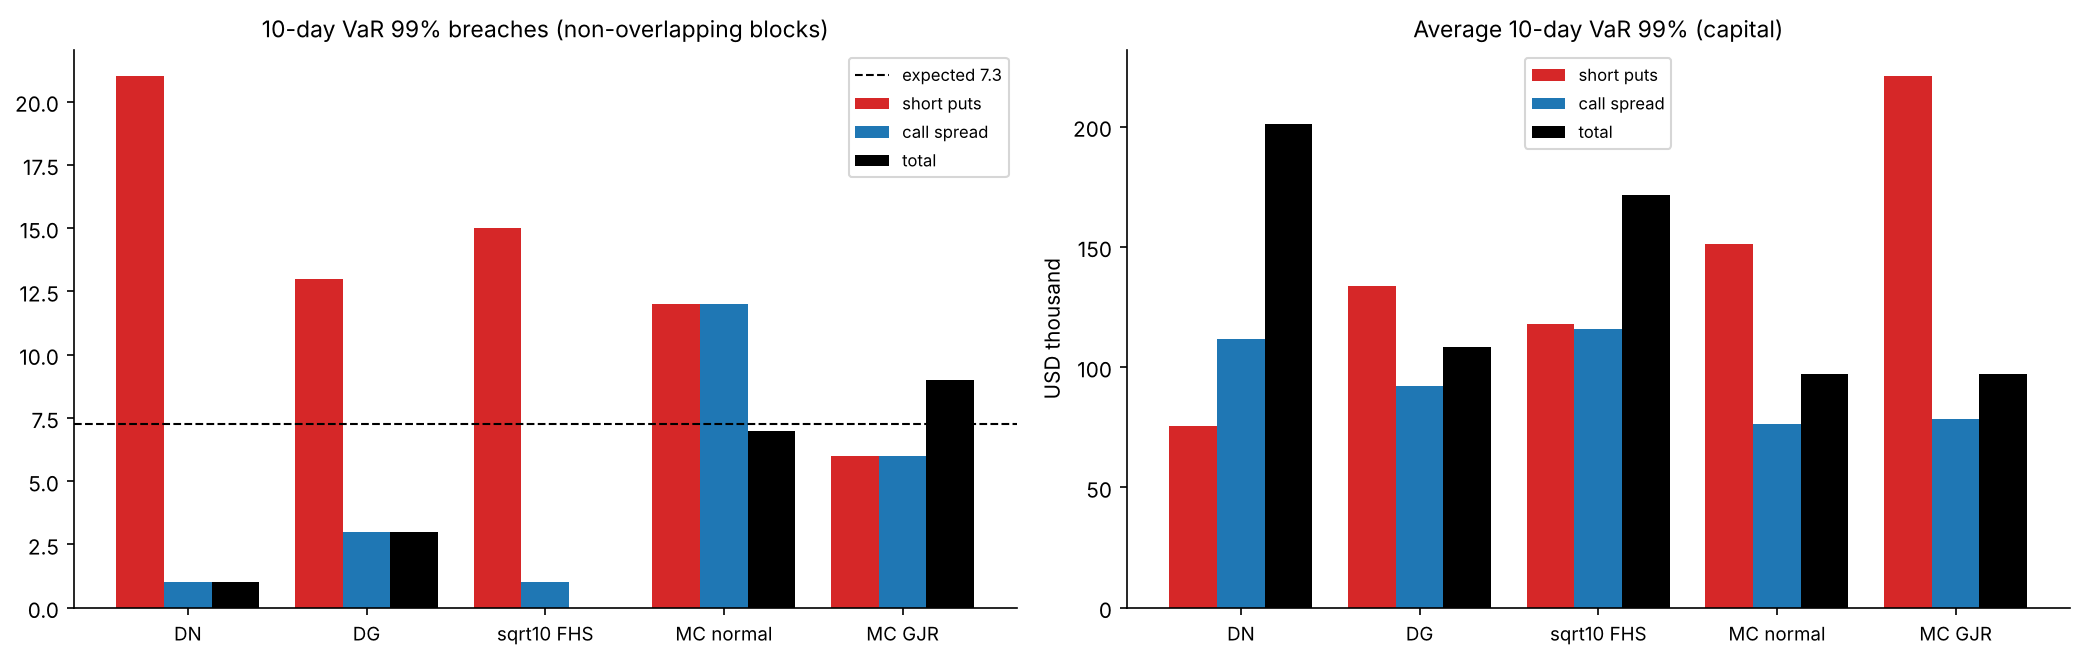

Average 10-day VaR relative to MC GJR (the only method that passes for every book):
            short puts  call spread  total
DN                0.34         1.42   2.07
DG                0.61         1.17   1.12
sqrt10 FHS        0.53         1.48   1.77
MC normal         0.68         0.97   1.00
MC GJR            1.00         1.00   1.00


In [ ]:
# 8.6 Chart: the ten-day backtest – breaches and capital per method (the 8.5 table)
tab10 = pd.DataFrame(rows).T                                 # rows = the 8.5 results
fig = plot_hday_backtest(tab10, 0.01 * nb)
fig.savefig(FIGURES / "backtest_10d.png", dpi=150, bbox_inches="tight")
plt.show()

rel = tab10["avg VaR 10d"].unstack(0)
print("Average 10-day VaR relative to MC GJR (the only method that passes for every book):")
print((rel / rel.loc["MC GJR"]).loc[["DN", "DG", "sqrt10 FHS", "MC normal", "MC GJR"],
                                   ["short puts", "call spread", "total"]].round(2).to_string())

**Findings – Section 8 (GJR-GARCH-t extension).** Full sample: α = 0, γ = 0.19, β = 0.895, ν = 7.3 (identical to `arch`): all the ARCH effect comes from falls; persistence 0.990 (half-life 72 days). Out of sample (414 fits, all converged) GJR beats EWMA on QLIKE (−8.383 vs −8.313). **FHS with GJR volatility passes all three tests for the short puts, the call spread and the book** (81 / 81 / 83 breaches vs 72.7, Christoffersen p 0.31–0.38, Z2 ≈ 0) with 2–6% less capital than FHS-EWMA. MC-t fails Z2 (−0.25 to −0.29): a symmetric t cannot produce the negative skew. **At ten days only Monte Carlo along GJR-t paths passes for every book** (6 / 6 / 9 breaches vs 7.3); √10 × FHS holds about half the capital needed for the short puts (15 breaches, Z2 −1.7) and 48–77% too much for the capped books; DN short puts: 21 breaches, Z2 −3.5. Worst 10-day loss of the short puts: −962k from 29 September 2008.

## 9. Vega: implied-volatility risk

Until now the VIX was held fixed in the scenarios. Here index and VIX move together, as they did on each historical day, and every forecast is tested against the full real P&L.

### 9.1 Joint index and VIX scenarios

| | |
|---|---|
| **1. What do I need to determine?** | VaR including the implied-volatility move of each scenario. |
| **2. What information and assumptions do I have?** | The same past day gives both an index return and a VIX log change. |
| **3. Which method is appropriate?** | Joint FHS: each move rescaled by its own volatility (GJR for the index, EWMA for VIX), full revaluation. |
| **4. Why should the method work?** | Taking both moves from the same day keeps their real dependence, including the crash-day VIX spikes. |
| **5. How can I verify the answer?** | Look-ahead test with a fake VIX spike; zero VIX changes reproduce index-only FHS. |

In [ ]:
# 9.1 Joint FHS with vega: look-ahead test, and the zero-VIX-change case equals index-only FHS-GJR

dlv_all = np.log(mkt["VIX"]).diff().iloc[1:]
ewma_vix = ewma_vol(dlv_all)

base = rolling_option_var_vega(mkt, gjr, ewma_vix, Q, start=5000, end=5005)

mkt_v = mkt.copy()
mkt_v.iloc[5003, mkt_v.columns.get_loc("VIX")] *= 3                     # fake VIX spike on return position 5002
fake = rolling_option_var_vega(mkt_v, gjr, ewma_vol(np.log(mkt_v["VIX"]).diff().iloc[1:]), Q, start=5000, end=5005)
col = ("short puts", "FHS-vega", "VaR")
print(pd.DataFrame({"base": base[col], "fake VIX spike": fake[col]}).round(0).to_string())
print(f"Unchanged up to the spike day: {np.allclose(base.iloc[:3].values, fake.iloc[:3].values)}")

mkt_0 = mkt.copy(); mkt_0["VIX"] = 20.0                                 # scenarios: no VIX change
# pricing still uses mkt_0["sigma"], which is unchanged (the real VIX / 100)
zero = rolling_option_var_vega(mkt_0, gjr, pd.Series(1.0, index=ret.index), Q, start=5000, end=5003)
print(f"\nVIX changes = 0 -> equals index-only FHS-GJR: "
      f"{np.allclose(zero.xs('FHS-vega', axis=1, level=1).values, oos_g.loc[zero.index].xs('FHS', axis=1, level=1).values)}")

                base  fake VIX spike
date                                
2009-11-05  107132.0        107132.0
2009-11-06   98937.0         98937.0
2009-11-09   91955.0         91955.0
2009-11-10   85526.0        241458.0
2009-11-11   80666.0        385037.0
Unchanged up to the spike day: True

VIX changes = 0 -> equals index-only FHS-GJR: True


### 9.2 Full run with vega, tested against the real P&L

| | |
|---|---|
| **1. What do I need to determine?** | Does joint FHS pass the tests against the full realised P&L? |
| **2. What information and assumptions do I have?** | 7,268 days, same dates as the GJR run. |
| **3. Which method is appropriate?** | Kupiec, Christoffersen and Z2 on the full P&L. |
| **4. Why should the method work?** | The full P&L is what the desk really makes; a risk model must explain it. |
| **5. How can I verify the answer?** | Compare with index-only FHS on the same days. |

In [ ]:
# 9.2 Full run with vega (joint FHS), backtested against the full realised P&L
v_file = OUT / "var_oos_vega.pkl"
if v_file.exists():
    oos_v = pd.read_pickle(v_file); print("Loaded from data/processed")
else:
    t0 = time.time()
    oos_v = rolling_option_var_vega(mkt, gjr, ewma_vix, Q, start=2000)
    oos_v.to_pickle(v_file); print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")
print(f"{len(oos_v):,} days, same dates as the GJR run: {oos_v.index.equals(oos_g.index)}; "
      f"missing: {int(oos_v.isna().sum().sum())}")

rf = real_full.loc[oos_v.index]
rows = {}
for b in ["long straddle", "short puts", "call spread", "total"]:
    for label, tab, m in [("FHS index only", oos_g, "FHS"), ("FHS-vega", oos_v, "FHS-vega")]:
        hits = (rf[b] < -tab[(b, m, "VaR")]).astype(int)
        x, pk = kupiec_test(hits); n11, pc = christoffersen_test(hits)
        z2 = acerbi_szekely_z2(rf[b], tab[(b, m, "VaR97.5")], tab[(b, m, "ES")])
        rows[(b, label)] = {"breaches": x, "Kupiec p": pk, "consec.": n11, "Christ. p": pc, "Z2": z2,
                            "avg VaR": tab[(b, m, "VaR")].mean(),
                            "pass all": (pk > 0.05) and (pc > 0.05) and (z2 > crit_g)}
print(f"\nFull realised P&L, expected breaches {0.01 * len(oos_v):.1f}, Z2 critical value {crit_g:.3f}:")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3f}" if abs(v) < 100 else f"{v:,.0f}"))

Computed in 0.8 minutes and saved
7,268 days, same dates as the GJR run: True; missing: 0

Full realised P&L, expected breaches 72.7, Z2 critical value -0.119:
                             breaches Kupiec p consec. Christ. p      Z2 avg VaR pass all
long straddle FHS index only     3323    0.000    1477     0.000 -41.165   5,889    False
              FHS-vega             80    0.396       1     0.692  -0.063  28,523     True
short puts    FHS index only      309    0.000      16     0.000  -2.660  37,416    False
              FHS-vega             80    0.396       3     0.139  -0.016  60,037     True
call spread   FHS index only       20    0.000       0     0.000   0.773  36,616    False
              FHS-vega             83    0.234       0     0.189   0.018  28,205     True
total         FHS index only        3    0.000       0     0.000   0.958  54,382    False
              FHS-vega             50    0.005       0     0.013   0.241  37,297    False


### 9.3 Chart: the backtest summary

| | |
|---|---|
| **1. What do I need to determine?** | All methods against the full P&L in one picture. |
| **2. What information and assumptions do I have?** | Breaches and Z2 for six methods and four books. |
| **3. Which method is appropriate?** | Grouped bars, log scale for breaches. |
| **4. Why should the method work?** | Only methods with bars near the line pass. |
| **5. How can I verify the answer?** | Same numbers as the table printed under the chart. |

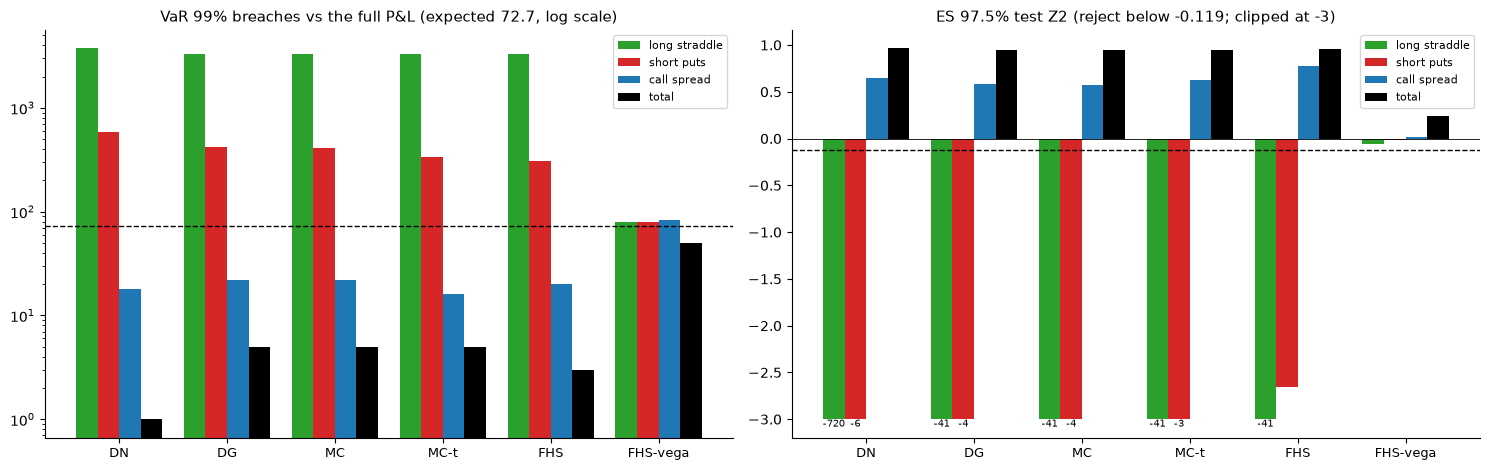

          call spread  long straddle  short puts  total
DG               22.0         3313.0       419.0    5.0
DN               18.0         3729.0       585.0    1.0
FHS              20.0         3323.0       309.0    3.0
FHS-vega         83.0           80.0        80.0   50.0
MC               22.0         3322.0       406.0    5.0
MC-t             16.0         3322.0       339.0    5.0


In [ ]:
# 9.3 Chart: backtest summary against the full realised P&L (GJR period, 7,268 days)

rows = {}
for b in ["long straddle", "short puts", "call spread", "total"]:
    for label, tab, m in [("DN", oos_g, "DN"), ("DG", oos_g, "DG"), ("MC", oos_g, "MC"), ("MC-t", oos_g, "MC-t"),
                          ("FHS", oos_g, "FHS"), ("FHS-vega", oos_v, "FHS-vega")]:
        rows[(b, label)] = {"breaches": int((rf[b] < -tab[(b, m, "VaR")]).sum()),
                            "Z2": acerbi_szekely_z2(rf[b], tab[(b, m, "VaR97.5")], tab[(b, m, "ES")])}
bt = pd.DataFrame(rows).T
fig = plot_backtest(bt, 0.01 * len(rf), crit_g)
fig.savefig(FIGURES / "backtest_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print(bt.unstack(0)["breaches"].to_string())

### 9.4 Chart: the short puts through two crises

| | |
|---|---|
| **1. What do I need to determine?** | How each model behaves day by day in 2008 and 2020. |
| **2. What information and assumptions do I have?** | Full P&L of the short puts; DN, index-only FHS and FHS-vega. |
| **3. Which method is appropriate?** | Bars (P&L) against −VaR lines. |
| **4. Why should the method work?** | Crises are when a risk model matters most. |
| **5. How can I verify the answer?** | Breach counts per crisis printed under the chart. |

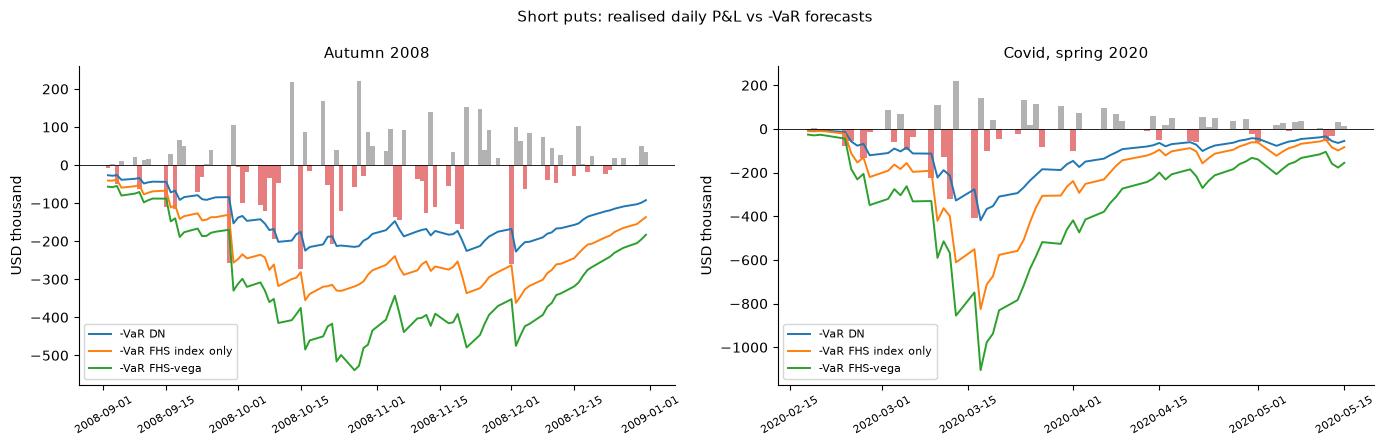

Autumn 2008: 85 days; breaches DN 9, FHS index only 5, FHS-vega 2
Covid, spring 2020: 63 days; breaches DN 9, FHS index only 5, FHS-vega 1


In [ ]:
# 9.4 Chart: short puts' daily P&L against DN, index-only FHS and FHS-vega through 2008 and 2020

lines = {"DN": oos_g[("short puts", "DN", "VaR")], "FHS index only": oos_g[("short puts", "FHS", "VaR")],
         "FHS-vega": oos_v[("short puts", "FHS-vega", "VaR")]}
crises = [("2008-09-01", "2008-12-31", "Autumn 2008"), ("2020-02-15", "2020-05-15", "Covid, spring 2020")]
fig = plot_var_through_crises(rf["short puts"], lines, crises, "Short puts: realised daily P&L vs -VaR forecasts")
fig.savefig(FIGURES / "var_through_crises.png", dpi=150, bbox_inches="tight")
plt.show()

for a, b, lab in crises:
    p = rf["short puts"].loc[a:b]
    print(f"{lab}: {len(p)} days; breaches " +
          ", ".join(f"{k} {int((p < -v.loc[a:b]).sum())}" for k, v in lines.items()))

**Findings – Section 9 (vega).** **Joint FHS of index and VIX moves (FHS-vega) passes all tests against the full real P&L** for the long straddle (80 breaches vs 72.7), the short puts (80) and the call spread (83); the whole book is conservative (50 breaches, Z2 +0.24). Ignoring vega leaves the straddle breaching on 46% of days and the short puts 4.3× too often. Vega changes the capital by ×4.8 (straddle), +60% (short puts), −23% (call spread) and −31% (book: its vega exposures partly offset). In the 2008 and 2020 crises DN is breached 9 times each, index-only FHS 5 times and FHS-vega only 2 and 1 times — on the first days, before volatility forecasts rose. The cost is procyclicality: in March 2020 FHS-vega asked for ~USD 1.1m while the worst day lost ~0.4m.

## 10. Conclusions

**Question:** how should a risk team measure the VaR of an options book, and how wrong are linear (delta-normal) approximations for non-linear positions?

**Data and book.** S&P 500 (Yahoo), VIX and 3-month T-bill (FRED), 9,269 common days (January 1990 – October 2026). A book of one-month SPX options priced with Black–Scholes at the VIX: a long ATM straddle, 5% OTM short puts and an ATM/105% call spread, USD 5m notional per 10 contracts, rebuilt daily at constant moneyness.

**Main findings**

1. **Options turn risk into shapes.** The book is long gamma at the money but its worst outcome is a moderate fall (about −5%), where the short puts' negative gamma dominates; Greeks are local.
2. **Delta-normal badly misstates option risk, in both directions.** One day: −26% for the short puts, +35% for the whole book; ten days: 2.9 times too low for the short puts and twice too high for the capped book. It fails every backtest (short puts: 3.2 times too many breaches, Z2 −1.53).
3. **Delta-gamma fixes the one-day valuation (within 1–6%) but not the ten-day one** (−34% to +21%): too low where gamma grows towards a strike, too high where the payoff is capped. Cornish–Fisher can even give a negative VaR.
4. **On one day, the tail matters more than the valuation:** DG and Monte Carlo with normal moves fail almost identically; FHS with fat-tailed historical scenarios is the only index-only method close to passing.
5. **GJR-GARCH (the extension) removes the remaining failure:** FHS with GJR volatility passes Kupiec, Christoffersen and Z2 for all books (index-only P&L) with 2–6% less capital than with EWMA. At ten days only Monte Carlo along GJR-t paths with full revaluation passes; √10 × the best one-day VaR is about half too low for the short puts and 48–77% too high for the capped books.
6. **Implied volatility is the largest single risk factor of the book.** Ignoring it leaves the long straddle breaching on 46% of days and the short puts 4 times too often; joint FHS of index returns and VIX changes passes all tests against the real P&L and moves the capital by ×4.8 (straddle), +60% (short puts), −23% (call spread), −31% (whole book).

**Recommendation**

- Daily VaR/ES of an options book: **full revaluation on joint index and implied-volatility scenarios (FHS), with GJR-GARCH volatility** — never delta-normal.
- Ten-day / regulatory horizon: **Monte Carlo along GARCH paths with full revaluation**, not √10.
- Report the Greeks (delta, gamma, vega, theta) for understanding and hedging, but not as a risk measure.

**Limitations.** Black–Scholes with one flat implied volatility (VIX) for all strikes — no smile or skew, so OTM puts are priced too cheaply and the index–vol hedge is simplified; constant dividend yield; European options rolled daily at constant moneyness; the realised P&L is itself model-based; the whole book's vega VaR is conservative (50 breaches vs 72.7); ten-day tests have low power (726 blocks).